# Tahap 3: Integrasi Data Kayu KLHK PHL, Staging PLTU, Kalkulasi Energi, & Star Schema Data Warehouse

Proyek Biomass & Waste-to-Energy Feedstock Finder menempatkan notebook ini sebagai tahap ke-4 dalam alur kerja tim (Tahap 3: *Advanced ETL, Energy Modeling & Data Warehouse*). Notebook ini membutuhkan artefak terverifikasi dari [01_eda_and_cleaning.ipynb](01_eda_and_cleaning.ipynb) dan [03_external_validation_and_screening.ipynb](03_external_validation_and_screening.ipynb) yang sudah tersimpan di `data/processed/`.

## Tujuan Notebook
1. Membersihkan dan menyatukan data produksi kayu bulat level provinsi dari KLHK PHL (`PBPH` dan `Perum Perhutani`, tahun `2018-2024`) serta menyematkan penanda *Dual-View* yang selaras dengan BDSP `kabkota`.
2. Melakukan pembersihan ringan (*staging*) pada tabel PLTU eksisting di `warehouse/tables/` (Climate TRACE `2021-2025` dan realisasi *co-firing* CREA `2024`) agar bebas duplikasi blok multi-unit, bebas penghitungan ganda kapasitas 2024, dan selaras dengan dimensi wilayah baru.
3. Menghubungkan data produksi BDSP `kabkota` (`FS01`-`FS08`) dan kayu KLHK PHL (`FS09`-`FS10`) ke profil tervalidasi Phyllis2 (`Bridge_Feedstock_Mapping`), lalu menghitung tonase residu *recoverable*, energi termal efektif berbasis LHV lapangan (`Total_Energy_Potential_GJ`), listrik (`Estimated_Generation_MWh`), daya (`Estimated_Capacity_MW`), substitusi batu bara, pengurangan emisi CO2e, dan beban abu.
4. Membangun *Data Warehouse* berpola *Kimball Multi-Fact Star Schema* (5 dimensi bersama + 2 tabel fakta + 5 *analytical views*) di direktori terpisah `warehouse_v2/` lengkap dengan pengujian integritas SQL (`PRAGMA foreign_key_check`), grafik perbandingan suplai vs PLTU, dan laporan QA otomatis.

## Daftar Input (*Read-Only*)
- `data/processed/phyllis2_10_validated.csv`
- `data/processed/bdsp_dim_kabkota.csv`
- `data/processed/bdsp_kabkota_clean.csv`
- `raw_data/02_bps/03_klhk_phl_kayu/{buku_2022,buku_2024}/` (4 file CSV `PBPH` dan `Perum Perhutani`)
- `warehouse/tables/{dim_power_plant.csv, fact_pltu_operations.csv, dim_data_source.csv, dim_location.csv}` (baca saja)

## Daftar Output yang Dihasilkan
- `data/processed/klhk_kayu_provinsi_clean.csv`
- `warehouse_v2/ddl_star_schema.sql`
- `warehouse_v2/biomass_dwh_v2.sqlite`
- `warehouse_v2/tables/` (7 CSV dimensi & fakta: `dim_feedstock.csv`, `dim_location.csv`, `dim_conversion_tech.csv`, `dim_time.csv`, `dim_power_plant.csv`, `fact_feedstock_potential.csv`, `fact_pltu_operations.csv`)
- `warehouse_v2/DWH_V2_QA_REPORT.md`
- `outputs/figures/04_dwh_supply_vs_pltu_dualview.png`

## 1. Persiapan Lingkungan & Pengaturan Direktori

Pada langkah ini pustaka pengolahan tabel, SQLite bawaan Python, dan visualisasi dimuat, lalu akar folder proyek dideteksi secara otomatis. Direktori `raw_data/` dan `warehouse/` lama diperlakukan sebagai sumber baca saja agar hasil lama tidak tertimpa, sementara seluruh keluaran *Data Warehouse* baru ditulis ke `warehouse_v2/`.

In [1]:
from pathlib import Path
from datetime import datetime
import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid", context="notebook")

cwd = Path.cwd().resolve()
PROJECT_ROOT = cwd.parent if cwd.name == "notebooks" else cwd
assert (PROJECT_ROOT / "raw_data").exists() and (PROJECT_ROOT / "warehouse").exists()

PROC_DIR = PROJECT_ROOT / "data" / "processed"
RAW_KLHK_DIR = PROJECT_ROOT / "raw_data" / "02_bps" / "03_klhk_phl_kayu"
OLD_WH_TABLES = PROJECT_ROOT / "warehouse" / "tables"
NEW_WH_DIR = PROJECT_ROOT / "warehouse_v2"
NEW_WH_TABLES = NEW_WH_DIR / "tables"
FIGURES_DIR = PROJECT_ROOT / "outputs" / "figures"

NEW_WH_TABLES.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print(f"PROJECT_ROOT  : {PROJECT_ROOT}")
print(f"PROC_DIR      : {PROC_DIR}")
print(f"OLD_WH_TABLES : {OLD_WH_TABLES} (read-only)")
print(f"NEW_WH_DIR    : {NEW_WH_DIR}")

PROJECT_ROOT  : D:\UPN VY\Semester 5\BI\Tugas\projectkb
PROC_DIR      : D:\UPN VY\Semester 5\BI\Tugas\projectkb\data\processed
OLD_WH_TABLES : D:\UPN VY\Semester 5\BI\Tugas\projectkb\warehouse\tables (read-only)
NEW_WH_DIR    : D:\UPN VY\Semester 5\BI\Tugas\projectkb\warehouse_v2


## 2. Pembersihan Data Kayu Bulat KLHK PHL (`klhk_kayu_provinsi_clean.csv`)

### Langkah Kerja dan Aturan Standarisasi
Produksi kayu bulat kehutanan diambil dari Statistik Ditjen PHL KLHK yang menggabungkan `PBPH` (Hutan Alam dan HTI) serta `Perum Perhutani` (4 provinsi Pulau Jawa). Pemilihan sumber ini mengikuti keputusan tim karena 89% kayu bulat nasional berasal dari HTI yang pada tabel BPS RI level pulau tidak dirinci per wilayah.

Aturan penyatuan yang diterapkan:
1. Mengambil tahun `2018-2019` dari edisi `buku_2022` dan tahun `2020-2024` dari edisi `buku_2024` setelah memverifikasi bahwa angka tahun tumpang tindih `2020-2022` identik 100% di kedua edisi buku.
2. Menyeragamkan 3 variasi penulisan nama provinsi (`Kep. Bangka Belitung`, `Kep.Riau`, dan `Nangroe Aceh Darussalam`) agar cocok 100% dengan `kode_prov` pada `bdsp_dim_kabkota.csv`.
3. Mengonversi volume $\text{m}^3$ ke estimasi tonase memakai $\rho = 0{,}65\text{ ton/m}^3$ sesuai `ref_rpr_parameters.csv`, menyematkan `cakupan_data = "KLHK_PHL_PBPH_PERHUTANI"` beserta flag *Dual-View* (`is_anchor_2022` pada 2022, `is_latest_complete_year` dan `is_latest_available_year` pada 2024), dan mempertahankan sel kosong asli sebagai `NaN` tanpa imputasi.

In [2]:
dim_kab = pd.read_csv(PROC_DIR / "bdsp_dim_kabkota.csv")
# Penyelarasan nama pulau agar cocok dengan 7 pulau pada data PLTU:
# BDSP menggabungkan Bali, NTB, NTT, Maluku, dan Maluku Utara ke 'Bali-Nusra-Maluku',
# sedangkan PLTU memisah 'Bali-Nusa Tenggara' (kode 51-53) dan 'Maluku' (kode 81-82).
def canonical_island(kode_prov: int, raw_pulau: str) -> str:
    if int(kode_prov) in (51, 52, 53):
        return "Bali-Nusa Tenggara"
    if int(kode_prov) in (81, 82):
        return "Maluku"
    return str(raw_pulau).strip()

dim_kab["pulau_std"] = [canonical_island(kp, pl) for kp, pl in zip(dim_kab["kode_prov"], dim_kab["pulau"])]
prov_lookup = (
    dim_kab[["kode_prov", "provinsi", "pulau_std"]]
    .drop_duplicates()
    .rename(columns={"pulau_std": "pulau"})
    .sort_values("kode_prov")
    .reset_index(drop=True)
)
assert len(prov_lookup) == 38

KLHK_PROV_RENAME = {
    "Kep. Bangka Belitung": "Kepulauan Bangka Belitung",
    "Kep.Riau": "Kepulauan Riau",
    "Nangroe Aceh Darussalam": "Aceh",
}
WOOD_DENSITY = 0.65

pb22 = pd.read_csv(RAW_KLHK_DIR / "buku_2022" / "tabel_pbph_provinsi_2018_2022.csv")
pb24 = pd.read_csv(RAW_KLHK_DIR / "buku_2024" / "tabel_3_9_pbph_provinsi_2020_2024.csv")
ph22 = pd.read_csv(RAW_KLHK_DIR / "buku_2022" / "tabel_perhutani_provinsi_2018_2022.csv")
ph24 = pd.read_csv(RAW_KLHK_DIR / "buku_2024" / "tabel_3_12_perhutani_provinsi_2020_2024.csv")

# Verifikasi kesamaan 100% pada tahun tumpang tindih 2020-2022 sebelum memilih edisi buku_2024
pb_check = pb22.merge(pb24, on="provinsi_pdf", suffixes=("_22", "_24"))
for yr in ["2020", "2021", "2022"]:
    diff_pb = (pb_check[f"{yr}_22"].fillna(0) - pb_check[f"{yr}_24"].fillna(0)).abs().max()
    assert diff_pb < 1e-6, f"Perbedaan PBPH tahun {yr}: {diff_pb}"
ph_check = ph22.merge(ph24, on="provinsi_pdf", suffixes=("_22", "_24"))
for yr in ["2020", "2021", "2022"]:
    diff_ph = (ph_check[f"{yr}_22"].fillna(0) - ph_check[f"{yr}_24"].fillna(0)).abs().max()
    assert diff_ph < 1e-6, f"Perbedaan Perhutani tahun {yr}: {diff_ph}"

def melt_klhk(df: pd.DataFrame, year_cols: list[str], segmen: str, edisi: str) -> pd.DataFrame:
    out = df.melt(
        id_vars=["provinsi_pdf", "sumber_instansi"],
        value_vars=year_cols,
        var_name="tahun",
        value_name="produksi_m3",
    )
    out["tahun"] = out["tahun"].astype(int)
    out["produksi_m3"] = pd.to_numeric(out["produksi_m3"], errors="coerce")
    out["segmen_kayu"] = segmen
    out["edisi_sumber"] = edisi
    return out

klhk_parts = [
    melt_klhk(pb22, ["2018", "2019"], "PBPH", "Statistik_PHL_2022"),
    melt_klhk(pb24, ["2020", "2021", "2022", "2023", "2024"], "PBPH", "Statistik_PHL_2024"),
    melt_klhk(ph22, ["2018", "2019"], "Perum Perhutani", "Statistik_PHL_2022"),
    melt_klhk(ph24, ["2020", "2021", "2022", "2023", "2024"], "Perum Perhutani", "Statistik_PHL_2024"),
]
df_klhk = pd.concat(klhk_parts, ignore_index=True)
df_klhk["provinsi"] = df_klhk["provinsi_pdf"].astype(str).str.strip().replace(KLHK_PROV_RENAME)

# Cocokkan 100% ke 38 provinsi kanonik
unmatched = set(df_klhk["provinsi"]) - set(prov_lookup["provinsi"])
assert len(unmatched) == 0, f"Provinsi KLHK gagal cocok: {unmatched}"
df_klhk = df_klhk.merge(prov_lookup, on="provinsi", how="left")

assert (df_klhk["produksi_m3"].dropna() < 0).sum() == 0
assert df_klhk.duplicated(subset=["kode_prov", "tahun", "segmen_kayu"]).sum() == 0

df_klhk["komoditas_bps"] = "Kayu"
df_klhk["basis_produk"] = "m3 Kayu Bulat (rho 0.65)"
df_klhk["satuan_asli"] = "m3"
df_klhk["produksi_ton_est"] = df_klhk["produksi_m3"] * WOOD_DENSITY
df_klhk["cakupan_data"] = "KLHK_PHL_PBPH_PERHUTANI"
df_klhk["is_anchor_2022"] = df_klhk["tahun"] == 2022
df_klhk["is_latest_complete_year"] = df_klhk["tahun"] == 2024
df_klhk["is_latest_available_year"] = df_klhk["tahun"] == 2024

df_klhk = df_klhk[[
    "kode_prov", "provinsi", "pulau", "tahun", "segmen_kayu", "komoditas_bps",
    "produksi_m3", "produksi_ton_est", "basis_produk", "satuan_asli",
    "cakupan_data", "is_anchor_2022", "is_latest_complete_year", "is_latest_available_year",
    "edisi_sumber",
]].sort_values(["tahun", "segmen_kayu", "kode_prov"]).reset_index(drop=True)

df_klhk.to_csv(PROC_DIR / "klhk_kayu_provinsi_clean.csv", index=False)

# Rekonsiliasi tahunan PBPH + Perhutani
klhk_reconcile = (
    df_klhk.pivot_table(index="tahun", columns="segmen_kayu", values="produksi_m3", aggfunc="sum")
    .fillna(0.0)
    .assign(Total_Kayu_Bulat_m3=lambda x: x["PBPH"] + x["Perum Perhutani"])
    .round(2)
)
assert abs(klhk_reconcile.loc[2022, "Total_Kayu_Bulat_m3"] - 55260218.00) <= 1.0
assert abs(klhk_reconcile.loc[2024, "Total_Kayu_Bulat_m3"] - 55547094.91) <= 1.0
print(f"Dimensi klhk_kayu_provinsi_clean.csv: {df_klhk.shape}")
display(klhk_reconcile)

Dimensi klhk_kayu_provinsi_clean.csv: (281, 15)


segmen_kayu,PBPH,Perum Perhutani,Total_Kayu_Bulat_m3
tahun,,,
2018,47113117.97,809934.0,47923051.97
2019,45763754.22,807888.0,46571642.22
2020,50661576.25,853701.0,51515277.25
2021,52483838.00,988708.0,53472546.00
2022,54325550.00,934668.0,55260218.00
2023,57341829.00,925101.0,58266930.00
2024,54730862.01,816232.9,55547094.91


**Interpretasi hasil pembersihan kayu KLHK PHL:**
Tabel rekonsiliasi menunjukkan total kayu bulat nasional dari gabungan PBPH dan Perum Perhutani sebesar `55.260.218,00 m3` pada tahun jangkar `2022` dan `55.547.094,91 m3` pada tahun lengkap terbaru `2024`, tepat nol selisih terhadap angka resmi buku Statistik PHL. Seluruh provinsi KLHK cocok ke kode 38 provinsi standar tanpa ada data kosong yang diisi perkiraan sendiri (termasuk provinsi `Papua Pegunungan` yang tidak tercatat di tabel KLHK 2024).

## 3. Penyusunan Dimensi Bersama (*Conformed Dimensions*) & Staging Data PLTU

### 3.1 Penyusunan `dim_feedstock`, `dim_location`, `dim_conversion_tech`, dan `dim_time`
Pada bagian ini keempat dimensi inti Star Schema dibentuk dari hasil Tahap 1 dan Tahap 2:
1. `dim_feedstock` memuat 10 profil biomassa bersih (`FS01`-`FS10`) dari `phyllis2_10_validated.csv` lengkap dengan `effective_lhv_field_mj_kg`, `rpr_alternatif_bps`, `recoverability_factor`, flag kelayakan boiler *rule-based*, risiko alkali/klorin, dan label klaster *K-Means*.
2. `dim_location` menyatukan tepat `560` baris wilayah tanpa duplikat (`1` nasional + `7` pulau selaras penamaan PLTU + `38` provinsi berkoordinat centroid + `514` kab/kota kanonik dari `bdsp_dim_kabkota.csv`). Penamaan pulau BDSP untuk provinsi `51-53` (`Bali-Nusa Tenggara`) dan `81-82` (`Maluku`) dipisah agar himpunan pulau pada suplai biomassa dan PLTU cocok 100%.
3. `dim_conversion_tech` memuat 2 teknologi pembangkit acuan Project Brief: `Co-Firing PLTU` (`TECH01`, efisiensi `33,0%`) dan `Gasifikasi Biomassa` (`TECH02`, efisiensi `25,45%`), dengan *capacity factor* acuan `70%` dan batas abu `< 10%` serta sulfur `< 0,5%`.
4. `dim_time` mencakup rentang tahun `2010-2025` dengan penanda era KSA, pemekaran Papua, tahun jangkar `2022`, dan ketersediaan data operasi PLTU Climate TRACE (`2021-2025`).

In [3]:
# --- 3.1 dim_feedstock (10 baris FS01-FS10) ---
phy_val = pd.read_csv(PROC_DIR / "phyllis2_10_validated.csv").sort_values("feedstock_id").reset_index(drop=True)
assert len(phy_val) == 10

dim_feedstock = pd.DataFrame({
    "feedstock_key": np.arange(1, len(phy_val) + 1, dtype=int),
    "feedstock_id": phy_val["feedstock_id"],
    "feedstock_name": phy_val["feedstock_name"],
    "komoditas_bps": phy_val["komoditas_bps"],
    "basis_produk_primer": phy_val["basis_produk_primer"],
    "rpr_primer": phy_val["rpr_primer"].round(4),
    "basis_alternatif_bps": phy_val["basis_alternatif_bps"],
    "rpr_alternatif_bps": phy_val["rpr_alternatif_bps"].round(4),
    "recoverability_factor": phy_val["recoverability_factor"].round(4),
    "moisture_lapangan_pct": phy_val["moisture_lapangan_pct"].round(2),
    "ash_db": phy_val["ash_db"].round(4),
    "vm_db": phy_val["vm_db"].round(4),
    "fc_db": phy_val["fc_db"].round(4),
    "c_db": phy_val["c_db"].round(4),
    "h_db": phy_val["h_db"].round(4),
    "o_db": phy_val["o_db"].round(4),
    "n_db": phy_val["n_db"].round(4),
    "s_db": phy_val["s_db"].round(4),
    "cl_db_pct": phy_val["cl_db_pct"].round(5),
    "alkali_total_db_pct": phy_val["alkali_total_db_pct"].round(5),
    "idt_oxidizing_c": phy_val["IDT_oxidizing_C"],
    "actual_hhv_db": phy_val["actual_hhv_db"].round(4),
    "predicted_hhv_prox_db": phy_val["predicted_hhv_prox_db"].round(4),
    "predicted_hhv_full_db": phy_val["predicted_hhv_full_db"].round(4),
    "predicted_hhv_db": phy_val["predicted_hhv_db"].round(4),
    "effective_lhv_lab_mj_kg": phy_val["effective_lhv_lab_mj_kg"].round(4),
    "effective_lhv_field_mj_kg": phy_val["effective_lhv_field_mj_kg"].round(4),
    "high_moisture_flag": phy_val["high_moisture_flag"].astype(int),
    "boiler_status": phy_val["boiler_status"],
    "is_boiler_eligible": (phy_val["boiler_status"] == "Eligible").astype(int),
    "alkali_chlorine_flag": phy_val["alkali_chlorine_flag"],
    "screening_recommendation": phy_val["screening_recommendation"],
    "cluster_id": phy_val["cluster_id"].astype(int),
    "cluster_label": phy_val["cluster_label"],
})

# --- 3.2 dim_conversion_tech (2 baris) ---
dim_conversion_tech = pd.DataFrame([
    {
        "tech_key": 1,
        "tech_code": "TECH01",
        "tech_name": "Co-Firing PLTU",
        "efficiency_pct": 33.0,
        "capacity_factor_pct": 70.0,
        "operating_hours_per_year": 8760 * 0.70,
        "ash_limit_pct": 10.0,
        "sulfur_limit_pct": 0.5,
        "reference_note": "Project Brief (efisiensi co-firing PLTU 30%-35%, titik tengah 33,0%; CREA 2025)",
    },
    {
        "tech_key": 2,
        "tech_code": "TECH02",
        "tech_name": "Gasifikasi Biomassa",
        "efficiency_pct": 25.45,
        "capacity_factor_pct": 70.0,
        "operating_hours_per_year": 8760 * 0.70,
        "ash_limit_pct": 10.0,
        "sulfur_limit_pct": 0.5,
        "reference_note": "Project Brief (efisiensi gasifikasi 25,45%; KTH Royal Institute of Technology 2026)",
    },
])

# --- 3.3 dim_time (16 baris: 2010-2025) ---
years_seq = list(range(2010, 2026))
dim_time = pd.DataFrame({
    "time_key": years_seq,
    "year": years_seq,
    "decade": [(y // 10) * 10 for y in years_seq],
    "is_bps_ksa_era": [1 if y >= 2018 else 0 for y in years_seq],
    "is_post_papua_split": [1 if y >= 2023 else 0 for y in years_seq],
    "is_anchor_2022": [1 if y == 2022 else 0 for y in years_seq],
    "has_pltu_ct_data": [1 if 2021 <= y <= 2025 else 0 for y in years_seq],
})

# --- 3.4 dim_location (560 baris: 1 Nasional + 7 Pulau + 38 Provinsi + 514 Kab/Kota) ---
old_loc = pd.read_csv(OLD_WH_TABLES / "dim_location.csv")
old_nat_row = old_loc.loc[old_loc["level_wilayah"] == "NASIONAL"].iloc[0]
old_pulau_map = (
    old_loc.loc[old_loc["level_wilayah"] == "PULAU"]
    .set_index("pulau")
    .to_dict("index")
)
old_prov_coords = (
    old_loc.loc[old_loc["level_wilayah"] == "PROVINSI"]
    .assign(kode_prov_int=lambda d: d["kode_bps_prov"].astype(float).astype(int))
    .set_index("kode_prov_int")
    .to_dict("index")
)

ISLANDS_ORDER = ["Sumatera", "Jawa", "Kalimantan", "Sulawesi", "Papua", "Bali-Nusa Tenggara", "Maluku"]
FIVE_PLTU_ISLANDS = {"Sumatera", "Jawa", "Kalimantan", "Sulawesi", "Papua"}
PLN_REGION_BY_ISLAND = {
    "Sumatera": "Sumatera",
    "Jawa": "JAMALI",
    "Kalimantan": "Kalimantan",
    "Sulawesi": "Sulawesi",
    "Papua": "Maluku-Papua",
    "Bali-Nusa Tenggara": "Nusa Tenggara",
    "Maluku": "Maluku-Papua",
}

loc_rows = []
# 1) 1 NASIONAL
loc_rows.append({
    "location_code": "IDN_00",
    "level_wilayah": "NASIONAL",
    "kode_prov": pd.NA,
    "nama_provinsi": "INDONESIA",
    "kode_kabkota": pd.NA,
    "nama_kabkota": None,
    "pulau": "Indonesia",
    "masuk_5_pulau_pltu": 0,
    "wilayah_pln": "Nasional",
    "latitude_centroid": round(float(old_nat_row["latitude_centroid"]), 4),
    "longitude_centroid": round(float(old_nat_row["longitude_centroid"]), 4),
    "has_coordinates": 1,
    "is_dob_papua_mapped": 0,
})

# 2) 7 PULAU (selaras dengan dim_power_plant)
for isl in ISLANDS_ORDER:
    ref = old_pulau_map[isl]
    loc_rows.append({
        "location_code": ref["location_code"],
        "level_wilayah": "PULAU",
        "kode_prov": pd.NA,
        "nama_provinsi": None,
        "kode_kabkota": pd.NA,
        "nama_kabkota": None,
        "pulau": isl,
        "masuk_5_pulau_pltu": 1 if isl in FIVE_PLTU_ISLANDS else 0,
        "wilayah_pln": PLN_REGION_BY_ISLAND[isl],
        "latitude_centroid": round(float(ref["latitude_centroid"]), 4),
        "longitude_centroid": round(float(ref["longitude_centroid"]), 4),
        "has_coordinates": 1,
        "is_dob_papua_mapped": 0,
    })

# 3) 38 PROVINSI
for _, pr in prov_lookup.iterrows():
    kp = int(pr["kode_prov"])
    ref_p = old_prov_coords[kp]
    isl = pr["pulau"]
    loc_rows.append({
        "location_code": f"PROV_{kp:02d}",
        "level_wilayah": "PROVINSI",
        "kode_prov": kp,
        "nama_provinsi": pr["provinsi"],
        "kode_kabkota": pd.NA,
        "nama_kabkota": None,
        "pulau": isl,
        "masuk_5_pulau_pltu": 1 if isl in FIVE_PLTU_ISLANDS else 0,
        "wilayah_pln": PLN_REGION_BY_ISLAND[isl],
        "latitude_centroid": round(float(ref_p["latitude_centroid"]), 4),
        "longitude_centroid": round(float(ref_p["longitude_centroid"]), 4),
        "has_coordinates": 1,
        "is_dob_papua_mapped": 0,
    })

# 4) 514 KABKOTA kanonik
for _, kr in dim_kab.sort_values("kode_kabkota").iterrows():
    kp = int(kr["kode_prov"])
    kk = int(kr["kode_kabkota"])
    isl = kr["pulau_std"]
    loc_rows.append({
        "location_code": f"KAB_{kk:04d}",
        "level_wilayah": "KABKOTA",
        "kode_prov": kp,
        "nama_provinsi": kr["provinsi"],
        "kode_kabkota": kk,
        "nama_kabkota": kr["kabupaten_kota"],
        "pulau": isl,
        "masuk_5_pulau_pltu": 1 if isl in FIVE_PLTU_ISLANDS else 0,
        "wilayah_pln": PLN_REGION_BY_ISLAND[isl],
        "latitude_centroid": np.nan,
        "longitude_centroid": np.nan,
        "has_coordinates": 0,
        "is_dob_papua_mapped": int(bool(kr["is_dob_papua_mapped"])),
    })

dim_location = pd.DataFrame(loc_rows)
dim_location.insert(0, "location_key", np.arange(1, len(dim_location) + 1, dtype=int))
dim_location["kode_prov"] = dim_location["kode_prov"].astype("Int64")
dim_location["kode_kabkota"] = dim_location["kode_kabkota"].astype("Int64")

assert len(dim_location) == 560
assert dim_location["level_wilayah"].value_counts().to_dict() == {
    "KABKOTA": 514, "PROVINSI": 38, "PULAU": 7, "NASIONAL": 1
}
print("Dimensi terbentuk:")
print(f"  dim_feedstock       : {dim_feedstock.shape}")
print(f"  dim_conversion_tech : {dim_conversion_tech.shape}")
print(f"  dim_time            : {dim_time.shape}")
print(f"  dim_location        : {dim_location.shape}")

Dimensi terbentuk:
  dim_feedstock       : (10, 34)
  dim_conversion_tech : (2, 9)
  dim_time            : (16, 7)
  dim_location        : (560, 14)


### 3.2 Pembersihan Ringan (*Staging*) Data PLTU (`dim_power_plant` & `fact_pltu_operations`)
Tabel PLTU eksisting di `warehouse/tables/` dibersihkan ringan tanpa mengubah direktori sumber aslinya:
1. Menyaring baris operasi ke dua sumber operasional aktif (`CLIMATETRACE_V6` tahun `2021-2025` berlabel `dataset_role = "BASE_OPERATIONS_CT"`, serta `CREA_MEI_2025` tahun `2024` berlabel `dataset_role = "COFIRING_REALIZATION_CREA"`) dan mengeluarkan 70 baris sekunder `WRI_GPPD_V130` (2017) agar tabel fakta bersih dari duplikasi data lama.
2. Mengagregasi 3 stasiun multi-blok pada `CREA_MEI_2025` (`Banten Suralaya` 3 blok, `PLN Paiton` 2 blok, dan `Tanjung Jati B` 2 blok; total 7 baris menjadi 3 baris stasiun sehingga memangkas 4 duplikat kunci) ke tingkat stasiun `(time_key = 2024, pltu_key)` memakai `sum(min_count=1)` agar angka `NaN` asli pada `Tanjung Jati B` tidak berubah menjadi nol palsu.
3. Menyaring `dim_power_plant` ke tepat `119` PLTU aktif (`100` Climate TRACE + `19` CREA-only; nol baris dimensi yatim), mendisambiguasi dua entri bernama `Banten Serang power station` menjadi `Banten Serang power station (PLTU_M064)` dan `Banten Serang power station (PLTU_M093)`, serta menandai `has_coordinates` (`0` untuk 18 PLTU tanpa koordinat) dan `name_audit_flag = "review_crea_pdf_name"` untuk 5 nama CREA yang terdistorsi.
4. Memetakan ulang `location_key` dari versi lama ke `dim_location` baru dan melepaskan placeholder `feedstock_key = 9` (`NON_COFIRING_COAL`).

In [4]:
old_dp = pd.read_csv(OLD_WH_TABLES / "dim_power_plant.csv")
old_fp = pd.read_csv(OLD_WH_TABLES / "fact_pltu_operations.csv")
old_ds = pd.read_csv(OLD_WH_TABLES / "dim_data_source.csv")

# Gabung kode sumber & lokasi lama untuk pemetaan ulang location_key ke dim_location baru
fp_raw = (
    old_fp
    .merge(old_ds[["source_key", "kode_sumber"]], on="source_key", how="left")
    .merge(old_loc[["location_key", "level_wilayah", "kode_bps_prov", "pulau"]], on="location_key", how="left")
)

# Saring hanya sumber operasional CT (2021-2025) dan CREA (2024)
fp_ct = fp_raw.loc[fp_raw["kode_sumber"] == "CLIMATETRACE_V6"].copy()
fp_crea_raw = fp_raw.loc[fp_raw["kode_sumber"] == "CREA_MEI_2025"].copy()

# Pemetaan location_key baru (PULAU lewat nama pulau; PROVINSI lewat kode_prov)
pulau_to_loc = dim_location.loc[dim_location["level_wilayah"] == "PULAU"].set_index("pulau")["location_key"].to_dict()
prov_to_loc = dim_location.loc[dim_location["level_wilayah"] == "PROVINSI"].set_index("kode_prov")["location_key"].to_dict()

def resolve_new_location_key(row) -> int:
    lvl = row["level_wilayah"]
    if lvl == "PULAU":
        return int(pulau_to_loc[row["pulau"]])
    if lvl == "PROVINSI":
        return int(prov_to_loc[int(float(row["kode_bps_prov"]))])
    raise ValueError(f"Level lokasi PLTU tidak diharapkan: {lvl}")

# Siapkan blok Climate TRACE (500 baris = 100 PLTU x 5 tahun)
fp_ct["new_location_key"] = [resolve_new_location_key(r) for _, r in fp_ct.iterrows()]
fp_ct["dataset_role"] = "BASE_OPERATIONS_CT"
fp_ct["crea_block_count"] = 1

# Agregasi CREA per (time_key, pltu_key) untuk mengatasi 3 stasiun multi-blok
fp_crea_raw["new_location_key"] = [resolve_new_location_key(r) for _, r in fp_crea_raw.iterrows()]
crea_agg_rows = []
for (t_yr, p_key), grp in fp_crea_raw.groupby(["time_key", "pltu_key"], sort=False):
    # Rata-rata tertimbang kapasitas hanya pada blok yang melaporkan cofiring_share_pct
    share_valid = grp.loc[grp["cofiring_share_pct"].notna() & (grp["capacity_mw"] > 0)]
    if len(share_valid) > 0:
        w_share = float((share_valid["cofiring_share_pct"] * share_valid["capacity_mw"]).sum() / share_valid["capacity_mw"].sum())
    else:
        w_share = np.nan

    # Jumlahkan dengan min_count=1 agar entri NaN asli (mis. Tanjung Jati B) tetap NULL
    crea_agg_rows.append({
        "time_key": int(t_yr),
        "new_location_key": int(grp["new_location_key"].iloc[0]),
        "pltu_key": int(p_key),
        "dataset_role": "COFIRING_REALIZATION_CREA",
        "kode_sumber": "CREA_MEI_2025",
        "crea_block_count": int(len(grp)),
        "capacity_mw": float(grp["capacity_mw"].sum(min_count=1)),
        "jumlah_unit": grp["jumlah_unit"].sum(min_count=1),
        "activity_generation_mwh": grp["activity_generation_mwh"].sum(min_count=1),
        "capacity_factor_pct": np.nan,
        "emissions_co2e_ton": grp["emissions_co2e_ton"].sum(min_count=1),
        "emissions_factor_t_per_mwh": np.nan,
        "cofiring_share_pct": round(w_share, 4) if pd.notna(w_share) else np.nan,
        "biomass_used_ton": grp["biomass_used_ton"].sum(min_count=1),
        "biomass_electricity_mwh": grp["biomass_electricity_mwh"].sum(min_count=1),
        "biomass_emissions_tco2": grp["biomass_emissions_tco2"].sum(min_count=1),
    })
fp_crea = pd.DataFrame(crea_agg_rows)

# Verifikasi total CREA pasca-agregasi sama persis dengan data mentah (18.342 MW, 1.457.720 ton, 1.506.076 MWh)
assert len(fp_crea) == 48
assert abs(fp_crea["capacity_mw"].sum() - 18342.0) < 1e-3
assert abs(fp_crea["biomass_used_ton"].sum() - 1457720.0) < 1e-3
assert abs(fp_crea["biomass_electricity_mwh"].sum() - 1506076.0) < 1e-3

cols_pltu_fact = [
    "time_key", "new_location_key", "pltu_key", "dataset_role", "kode_sumber", "crea_block_count",
    "capacity_mw", "jumlah_unit", "activity_generation_mwh", "capacity_factor_pct",
    "emissions_co2e_ton", "emissions_factor_t_per_mwh", "cofiring_share_pct",
    "biomass_used_ton", "biomass_electricity_mwh", "biomass_emissions_tco2",
]
fp_ct_clean = fp_ct.assign(dataset_role="BASE_OPERATIONS_CT", crea_block_count=1)[cols_pltu_fact]
fact_pltu_operations = (
    pd.concat([fp_ct_clean, fp_crea[cols_pltu_fact]], ignore_index=True)
    .rename(columns={"new_location_key": "location_key"})
    .sort_values(["dataset_role", "time_key", "pltu_key"])
    .reset_index(drop=True)
)
fact_pltu_operations.insert(0, "pltu_fact_id", np.arange(1, len(fact_pltu_operations) + 1, dtype=int))
fact_pltu_operations["jumlah_unit"] = fact_pltu_operations["jumlah_unit"].astype("Int64")

assert len(fact_pltu_operations) == 548
assert fact_pltu_operations.duplicated(subset=["time_key", "pltu_key", "dataset_role"]).sum() == 0

# Susun dim_power_plant bersih (hanya 119 PLTU aktif)
active_pltu_keys = set(fact_pltu_operations["pltu_key"].unique())
dim_power_plant = old_dp.loc[old_dp["pltu_key"].isin(active_pltu_keys)].copy()

# Disambiguasi 2 baris bernama kembar 'Banten Serang power station'
dup_serang = dim_power_plant["nama_pltu_standar"] == "Banten Serang power station"
dim_power_plant.loc[dup_serang, "nama_pltu_standar"] = (
    dim_power_plant.loc[dup_serang, "nama_pltu_standar"]
    + " (" + dim_power_plant.loc[dup_serang, "pltu_master_id"] + ")"
)

DISTORTED_CREA_NAMES = {
    "PLTU Pakaian 1-2",
    "PLTU Jadi Tanasa 1-3",
    "PLTU Angka 1-2",
    "PLTU Dia 1-2",
    "PLTU Berlawanan 1-2",
}
dim_power_plant["has_coordinates"] = (
    dim_power_plant["latitude"].notna() & dim_power_plant["longitude"].notna()
).astype(int)
dim_power_plant["name_audit_flag"] = np.where(
    dim_power_plant["nama_pltu_standar"].isin(DISTORTED_CREA_NAMES),
    "review_crea_pdf_name",
    "ok",
)
dim_power_plant["commissioning_year"] = dim_power_plant["commissioning_year"].astype("Int64")
dim_power_plant = dim_power_plant[[
    "pltu_key", "pltu_master_id", "nama_pltu_standar", "nama_climatetrace",
    "nama_wri_gppd", "nama_crea_2025", "owner_operator", "jenis_boiler",
    "status_cofiring_2024", "commissioning_year", "latitude", "longitude",
    "has_coordinates", "pulau", "masuk_5_pulau_pltu", "wilayah_pln",
    "entity_match_method", "name_audit_flag",
]].sort_values("pltu_key").reset_index(drop=True)

assert len(dim_power_plant) == 119
assert dim_power_plant["nama_pltu_standar"].nunique() == 119
assert set(dim_power_plant["pulau"]) == set(dim_location.loc[dim_location["level_wilayah"] != "NASIONAL", "pulau"])

print(f"Dimensi dim_power_plant       : {dim_power_plant.shape} (has_coordinates=1: {int(dim_power_plant['has_coordinates'].sum())}, 0: {int((dim_power_plant['has_coordinates']==0).sum())})")
print(f"Dimensi fact_pltu_operations  : {fact_pltu_operations.shape}")
display(fact_pltu_operations.groupby(["dataset_role", "time_key"]).agg(
    baris=("pltu_fact_id", "size"),
    kapasitas_mw=("capacity_mw", "sum"),
    generasi_mwh=("activity_generation_mwh", "sum"),
    biomassa_ton=("biomass_used_ton", "sum"),
    listrik_biomassa_mwh=("biomass_electricity_mwh", "sum"),
).round(1))

Dimensi dim_power_plant       : (119, 18) (has_coordinates=1: 101, 0: 18)
Dimensi fact_pltu_operations  : (548, 17)


baris  kapasitas_mw  generasi_mwh  biomassa_ton  listrik_biomassa_mwh
dataset_role              time_key                                                                       
BASE_OPERATIONS_CT        2021        100       41306.7   184903973.0           0.0                   0.0
                          2022        100       48514.7   218013203.3           0.0                   0.0
                          2023        100       53928.7   225731213.1           0.0                   0.0
                          2024        100       56263.7   237741864.6           0.0                   0.0
                          2025        100       59718.7   251814322.3           0.0                   0.0
COFIRING_REALIZATION_CREA 2024         48       18342.0           0.0     1457720.0             1506076.0

**Interpretasi hasil *staging* data PLTU:**
Seluruh 119 PLTU aktif telah memiliki nama unik setelah disambiguasi `Banten Serang power station (PLTU_M064)` dan `(PLTU_M093)`. Tabel fakta `fact_pltu_operations` berisi `500` baris operasi tahunan Climate TRACE (`2021-2025`) dan `48` baris realisasi stasiun CREA (`2024`) dengan pemisahan peran tegas (`dataset_role`) sehingga total kapasitas dan pembangkitan tidak mengalami penghitungan ganda.

## 4. `Bridge_Feedstock_Mapping` & Kalkulasi Potensi Energi (`fact_feedstock_potential`)

### Rumus Konversi Fisika dan Energi
Komoditas BDSP `kabkota` (`Padi`, `Jagung`, `Kelapa Sawit`, `Tebu` di `514` kab/kota, `2010-2025`) dan kayu KLHK PHL (agregasi `PBPH + Perum Perhutani` per provinsi, `2018-2024`) dihubungkan ke 10 profil tervalidasi `dim_feedstock` (`FS01`-`FS10`) lewat kunci `komoditas_bps`, disaring untuk nilai produksi positif (`> 0`), lalu disilangkan dengan dua teknologi pada `dim_conversion_tech`.

Rumus yang diterapkan pada setiap baris:
- $\text{Estimated\_Supply\_Gross\_Tons} = \text{Produksi\_Komoditas} \times \text{rpr\_alternatif\_bps}$
- $\text{Estimated\_Supply\_Tons} = \text{Estimated\_Supply\_Gross\_Tons} \times \text{recoverability\_factor}$
- $\text{Total\_Energy\_Potential\_GJ} = \text{Estimated\_Supply\_Tons} \times \text{effective\_lhv\_field\_mj\_kg}$ (dengan konversi tepat $1\text{ ton} \times 1\text{ MJ/kg} = 1\text{ GJ}$)
- $\text{Estimated\_Generation\_MWh} = (\text{Total\_Energy\_Potential\_GJ} \times (\text{efficiency\_pct} / 100)) / 3{,}6$
- $\text{Estimated\_Capacity\_MW} = \text{Estimated\_Generation\_MWh} / (8760 \times 0{,}70)$
- $\text{Coal\_Replaced\_Tons} = \text{Total\_Energy\_Potential\_GJ} / 20{,}0$ (acuan batu bara kalori menengah `20,0 MJ/kg` dari kisaran 18-22 MJ/kg pada Project Brief)
- $\text{CO2\_Offset\_Tons} = \text{Total\_Energy\_Potential\_GJ} \times 0{,}0946$ (faktor emisi default batu bara IPCC)
- $\text{Ash\_Load\_Tons} = \text{Estimated\_Supply\_Tons} \times (1 - \text{moisture\_lapangan\_pct}/100) \times (\text{ash\_db}/100)$

In [5]:
bdsp_clean = pd.read_csv(PROC_DIR / "bdsp_kabkota_clean.csv")
klhk_clean = pd.read_csv(PROC_DIR / "klhk_kayu_provinsi_clean.csv")

# Peta location_key untuk level KABKOTA dan PROVINSI
kab_to_loc = dim_location.loc[dim_location["level_wilayah"] == "KABKOTA"].set_index("kode_kabkota")["location_key"].to_dict()
prov_to_loc = dim_location.loc[dim_location["level_wilayah"] == "PROVINSI"].set_index("kode_prov")["location_key"].to_dict()

# 1) Siapkan data pasokan BDSP kabkota positif (> 0)
bdsp_pos = bdsp_clean.loc[bdsp_clean["produksi_ton"].notna() & (bdsp_clean["produksi_ton"] > 0)].copy()
bdsp_pos["location_key"] = bdsp_pos["kode_kabkota"].map(kab_to_loc).astype(int)
bdsp_pos["level_wilayah_fakta"] = "KABKOTA"
bdsp_pos = bdsp_pos.rename(columns={
    "tahun": "time_key",
    "produksi_ton": "commodity_production_val",
    "satuan_asli": "commodity_unit",
})[[
    "time_key", "location_key", "level_wilayah_fakta", "komoditas_bps",
    "commodity_production_val", "commodity_unit", "sumber_data", "cakupan_data",
    "is_anchor_2022", "is_latest_complete_year", "is_latest_available_year",
]]

# 2) Agregasikan KLHK PHL (PBPH + Perum Perhutani) per (kode_prov, tahun) agar 1 baris per (provinsi, tahun)
klhk_agg = (
    klhk_clean
    .groupby(["kode_prov", "tahun", "komoditas_bps", "satuan_asli", "cakupan_data",
              "is_anchor_2022", "is_latest_complete_year", "is_latest_available_year"], as_index=False)["produksi_m3"]
    .sum(min_count=1)
)
klhk_pos = klhk_agg.loc[klhk_agg["produksi_m3"].notna() & (klhk_agg["produksi_m3"] > 0)].copy()
klhk_pos["location_key"] = klhk_pos["kode_prov"].map(prov_to_loc).astype(int)
klhk_pos["level_wilayah_fakta"] = "PROVINSI"
klhk_pos["sumber_data"] = "KLHK_PHL_PROVINSI"
klhk_pos = klhk_pos.rename(columns={
    "tahun": "time_key",
    "produksi_m3": "commodity_production_val",
    "satuan_asli": "commodity_unit",
})[[
    "time_key", "location_key", "level_wilayah_fakta", "komoditas_bps",
    "commodity_production_val", "commodity_unit", "sumber_data", "cakupan_data",
    "is_anchor_2022", "is_latest_complete_year", "is_latest_available_year",
]]

prod_unified = pd.concat([bdsp_pos, klhk_pos], ignore_index=True)

# 3) Bridge_Feedstock_Mapping: gabungkan produksi ke dim_feedstock pada komoditas_bps
bridge_cols = [
    "feedstock_key", "komoditas_bps", "rpr_alternatif_bps", "recoverability_factor",
    "moisture_lapangan_pct", "ash_db", "predicted_hhv_db", "effective_lhv_field_mj_kg",
    "is_boiler_eligible",
]
prod_mapped = prod_unified.merge(dim_feedstock[bridge_cols], on="komoditas_bps", how="inner")

# 4) Silangkan dengan dim_conversion_tech (TECH01 Co-Firing PLTU 33%, TECH02 Gasifikasi 25,45%)
fact_df = prod_mapped.merge(
    dim_conversion_tech[["tech_key", "efficiency_pct", "operating_hours_per_year"]],
    how="cross",
)

COAL_REF_HHV_MJ_KG = 20.0
IPCC_COAL_EF_T_CO2_PER_GJ = 0.0946

fact_df["estimated_supply_gross_tons"] = fact_df["commodity_production_val"] * fact_df["rpr_alternatif_bps"]
fact_df["estimated_supply_tons"] = fact_df["estimated_supply_gross_tons"] * fact_df["recoverability_factor"]
fact_df["total_energy_potential_gj"] = fact_df["estimated_supply_tons"] * fact_df["effective_lhv_field_mj_kg"]
fact_df["estimated_generation_mwh"] = (fact_df["total_energy_potential_gj"] * (fact_df["efficiency_pct"] / 100.0)) / 3.6
fact_df["estimated_capacity_mw"] = fact_df["estimated_generation_mwh"] / fact_df["operating_hours_per_year"]
fact_df["coal_replaced_tons"] = fact_df["total_energy_potential_gj"] / COAL_REF_HHV_MJ_KG
fact_df["co2_offset_tons"] = fact_df["total_energy_potential_gj"] * IPCC_COAL_EF_T_CO2_PER_GJ
fact_df["ash_load_tons"] = (
    fact_df["estimated_supply_tons"]
    * (1.0 - fact_df["moisture_lapangan_pct"] / 100.0)
    * (fact_df["ash_db"] / 100.0)
)

# Pembulatan rapi untuk output CSV dan SQLite (ketepatan jauh lebih ketat dari toleransi 0,01)
for c_round in [
    "estimated_supply_gross_tons", "estimated_supply_tons", "total_energy_potential_gj",
    "estimated_generation_mwh", "estimated_capacity_mw", "coal_replaced_tons",
    "co2_offset_tons", "ash_load_tons",
]:
    fact_df[c_round] = fact_df[c_round].round(4)

for bcol in ["is_anchor_2022", "is_latest_complete_year", "is_latest_available_year", "is_boiler_eligible"]:
    fact_df[bcol] = fact_df[bcol].astype(int)

fact_feedstock_potential = fact_df[[
    "time_key", "location_key", "feedstock_key", "tech_key", "level_wilayah_fakta",
    "sumber_data", "cakupan_data", "is_anchor_2022", "is_latest_complete_year",
    "is_latest_available_year", "is_boiler_eligible",
    "commodity_production_val", "commodity_unit",
    "rpr_alternatif_bps", "recoverability_factor",
    "estimated_supply_gross_tons", "estimated_supply_tons",
    "moisture_lapangan_pct", "predicted_hhv_db", "effective_lhv_field_mj_kg",
    "total_energy_potential_gj", "estimated_generation_mwh", "estimated_capacity_mw",
    "coal_replaced_tons", "co2_offset_tons", "ash_load_tons",
]].rename(columns={
    "rpr_alternatif_bps": "rpr_ratio_used",
    "recoverability_factor": "recoverability_factor_used",
    "predicted_hhv_db": "predicted_hhv_mj_kg",
    "effective_lhv_field_mj_kg": "effective_lhv_mj_kg",
}).sort_values(["time_key", "location_key", "feedstock_key", "tech_key"]).reset_index(drop=True)

fact_feedstock_potential.insert(0, "energy_fact_id", np.arange(1, len(fact_feedstock_potential) + 1, dtype=int))

assert fact_feedstock_potential.duplicated(subset=["time_key", "location_key", "feedstock_key", "tech_key"]).sum() == 0
print(f"Dimensi fact_feedstock_potential: {fact_feedstock_potential.shape}")

# Ringkasan potensi per feedstock (Co-Firing PLTU TECH01) pada mode Dual-View
summary_dv = (
    fact_feedstock_potential
    .loc[fact_feedstock_potential["tech_key"] == 1]
    .merge(dim_feedstock[["feedstock_key", "feedstock_id", "feedstock_name", "boiler_status"]], on="feedstock_key")
)
for mode_col, label in [("is_anchor_2022", "Anchor 2022"), ("is_latest_complete_year", "Latest Complete Year")]:
    print(f"\nRingkasan Potensi Nasional ({label}, TECH01 Co-Firing 33%):")
    tbl = (
        summary_dv.loc[summary_dv[mode_col] == 1]
        .groupby(["feedstock_id", "feedstock_name", "boiler_status", "is_boiler_eligible"], as_index=False)
        .agg(
            tahun=("time_key", "first"),
            suplai_juta_ton=("estimated_supply_tons", lambda s: s.sum() / 1e6),
            energi_pj=("total_energy_potential_gj", lambda s: s.sum() / 1e6),
            listrik_twh=("estimated_generation_mwh", lambda s: s.sum() / 1e6),
            daya_mw=("estimated_capacity_mw", "sum"),
            co2_offset_juta_ton=("co2_offset_tons", lambda s: s.sum() / 1e6),
        )
        .round(3)
    )
    display(tbl)

Dimensi fact_feedstock_potential: (69686, 27)

Ringkasan Potensi Nasional (Anchor 2022, TECH01 Co-Firing 33%):


,feedstock_id,feedstock_name,boiler_status,is_boiler_eligible,tahun,suplai_juta_ton,energi_pj,listrik_twh,daya_mw,co2_offset_juta_ton
0,FS01,palm kernel shell,Eligible,1,2022,3.849,58.797,5.390,878.951,5.562
1,FS02,empty fruit bunches,Eligible,1,2022,11.079,72.668,6.661,1086.309,6.874
2,FS03,palm fiber,Eligible,1,2022,7.524,72.194,6.618,1079.215,6.830
3,FS04,rice husk,Not Eligible,0,2022,11.607,146.768,13.454,2194.016,13.884
4,FS05,rice straw,Not Eligible,0,2022,38.189,464.925,42.618,6950.115,43.982
5,FS06,bagasse,Eligible,1,2022,7.443,53.368,4.892,797.792,5.049
6,FS07,corn cob,Eligible,1,2022,1.220,17.894,1.640,267.502,1.693
7,FS08,corn stover,Eligible,1,2022,5.584,78.197,7.168,1168.965,7.397
8,FS09,sawdust,Eligible,1,2022,3.448,49.436,4.532,739.014,4.677
9,FS10,wood chips,Eligible,1,2022,8.549,110.847,10.161,1657.035,10.486



Ringkasan Potensi Nasional (Latest Complete Year, TECH01 Co-Firing 33%):


,feedstock_id,feedstock_name,boiler_status,is_boiler_eligible,tahun,suplai_juta_ton,energi_pj,listrik_twh,daya_mw,co2_offset_juta_ton
0,FS01,palm kernel shell,Eligible,1,2024,4.005,61.176,5.608,914.520,5.787
1,FS02,empty fruit bunches,Eligible,1,2024,11.527,75.609,6.931,1130.272,7.153
2,FS03,palm fiber,Eligible,1,2024,7.829,75.115,6.886,1122.890,7.106
3,FS04,rice husk,Not Eligible,0,2025,12.860,162.618,14.907,2430.965,15.384
4,FS05,rice straw,Not Eligible,0,2025,42.313,515.136,47.221,7700.712,48.732
5,FS06,bagasse,Eligible,1,2022,7.443,53.368,4.892,797.792,5.049
6,FS07,corn cob,Eligible,1,2017,5.628,82.582,7.570,1234.509,7.812
7,FS08,corn stover,Eligible,1,2017,25.770,360.877,33.080,5394.723,34.139
8,FS09,sawdust,Eligible,1,2024,3.466,49.693,4.555,742.850,4.701
9,FS10,wood chips,Eligible,1,2024,8.593,111.422,10.214,1665.637,10.541


**Interpretasi hasil kalkulasi potensi energi daerah:**
Penggunaan `recoverability_factor` dan `effective_lhv_field_mj_kg` memberikan angka potensi yang jauh lebih realistis dibanding perhitungan kasar berbasis HHV kering tanpa koreksi kelembapan (terutama pada TKKS sawit berkadar air 55% dan ampas tebu berkadar air 50%). Selain itu, sekam padi (`FS04`) dan jerami padi (`FS05`) berstatus `Not Eligible` (`is_boiler_eligible = 0`), sehingga kontribusinya terisolasi dari perhitungan pasokan pembangkit pada tampilan analitik PLTU.

## 5. Pembangunan Database SQLite (`warehouse_v2/`) & *Analytical Views*

Skrip DDL `warehouse_v2/ddl_star_schema.sql` ditulis lengkap dengan kunci utama (*Primary Key*), kunci asing (*Foreign Key*) yang diaktifkan lewat `PRAGMA foreign_keys = ON`, indeks kueri OLAP, serta lima *views* siap pakai untuk *Dashboard BI* Tahap 4. Setelah seluruh 7 tabel diekspor ke `warehouse_v2/tables/`, isi tabel dimuat ke `warehouse_v2/biomass_dwh_v2.sqlite` dan diuji integritasnya.

In [6]:
ddl_sql = '''-- =============================================================================
-- STAR SCHEMA DATA WAREHOUSE V2 (PROJECTKB - Biomass & PLTU Co-Firing BI)
-- Kompatibel: SQLite 3 (native), DuckDB, dan portabel ke PostgreSQL
-- Pola: Kimball Multi-Fact Star Schema (5 Conformed Dimensions + 2 Fact Tables)
-- =============================================================================

PRAGMA foreign_keys = ON;

DROP VIEW IF EXISTS vw_cofiring_simulator_base;
DROP VIEW IF EXISTS vw_supply_vs_pltu_5_pulau_dualview;
DROP VIEW IF EXISTS vw_regional_potential_latest_complete;
DROP VIEW IF EXISTS vw_regional_potential_anchor_2022;
DROP VIEW IF EXISTS vw_feedstock_discovery_matrix;

DROP TABLE IF EXISTS fact_pltu_operations;
DROP TABLE IF EXISTS fact_feedstock_potential;
DROP TABLE IF EXISTS dim_power_plant;
DROP TABLE IF EXISTS dim_time;
DROP TABLE IF EXISTS dim_conversion_tech;
DROP TABLE IF EXISTS dim_location;
DROP TABLE IF EXISTS dim_feedstock;

-- -----------------------------------------------------------------------------
-- 1. CONFORMED DIMENSIONS (5 TABEL)
-- -----------------------------------------------------------------------------

CREATE TABLE dim_feedstock (
    feedstock_key              INTEGER PRIMARY KEY,
    feedstock_id               TEXT NOT NULL UNIQUE,
    feedstock_name             TEXT NOT NULL,
    komoditas_bps              TEXT NOT NULL,
    basis_produk_primer        TEXT NOT NULL,
    rpr_primer                 REAL NOT NULL,
    basis_alternatif_bps       TEXT NOT NULL,
    rpr_alternatif_bps         REAL NOT NULL,
    recoverability_factor      REAL NOT NULL,
    moisture_lapangan_pct      REAL NOT NULL,
    ash_db                     REAL NOT NULL,
    vm_db                      REAL NOT NULL,
    fc_db                      REAL NOT NULL,
    c_db                       REAL NOT NULL,
    h_db                       REAL NOT NULL,
    o_db                       REAL NOT NULL,
    n_db                       REAL NOT NULL,
    s_db                       REAL NOT NULL,
    cl_db_pct                  REAL,
    alkali_total_db_pct        REAL,
    idt_oxidizing_c            REAL,
    actual_hhv_db              REAL NOT NULL,
    predicted_hhv_prox_db      REAL NOT NULL,
    predicted_hhv_full_db      REAL NOT NULL,
    predicted_hhv_db           REAL NOT NULL,
    effective_lhv_lab_mj_kg    REAL NOT NULL,
    effective_lhv_field_mj_kg  REAL NOT NULL,
    high_moisture_flag         INTEGER NOT NULL CHECK (high_moisture_flag IN (0, 1)),
    boiler_status              TEXT NOT NULL CHECK (boiler_status IN ('Eligible', 'Not Eligible')),
    is_boiler_eligible         INTEGER NOT NULL CHECK (is_boiler_eligible IN (0, 1)),
    alkali_chlorine_flag       TEXT NOT NULL,
    screening_recommendation   TEXT NOT NULL,
    cluster_id                 INTEGER NOT NULL,
    cluster_label              TEXT NOT NULL
);

CREATE TABLE dim_location (
    location_key         INTEGER PRIMARY KEY,
    location_code        TEXT NOT NULL UNIQUE,
    level_wilayah        TEXT NOT NULL CHECK (level_wilayah IN ('NASIONAL', 'PULAU', 'PROVINSI', 'KABKOTA')),
    kode_prov            INTEGER,
    nama_provinsi        TEXT,
    kode_kabkota         INTEGER,
    nama_kabkota         TEXT,
    pulau                TEXT NOT NULL,
    masuk_5_pulau_pltu   INTEGER NOT NULL CHECK (masuk_5_pulau_pltu IN (0, 1)),
    wilayah_pln          TEXT NOT NULL,
    latitude_centroid    REAL,
    longitude_centroid   REAL,
    has_coordinates      INTEGER NOT NULL CHECK (has_coordinates IN (0, 1)),
    is_dob_papua_mapped  INTEGER NOT NULL CHECK (is_dob_papua_mapped IN (0, 1))
);

CREATE TABLE dim_conversion_tech (
    tech_key                  INTEGER PRIMARY KEY,
    tech_code                 TEXT NOT NULL UNIQUE,
    tech_name                 TEXT NOT NULL,
    efficiency_pct            REAL NOT NULL,
    capacity_factor_pct       REAL NOT NULL,
    operating_hours_per_year  REAL NOT NULL,
    ash_limit_pct             REAL NOT NULL,
    sulfur_limit_pct          REAL NOT NULL,
    reference_note            TEXT NOT NULL
);

CREATE TABLE dim_time (
    time_key             INTEGER PRIMARY KEY,
    year                 INTEGER NOT NULL UNIQUE,
    decade               INTEGER NOT NULL,
    is_bps_ksa_era       INTEGER NOT NULL CHECK (is_bps_ksa_era IN (0, 1)),
    is_post_papua_split  INTEGER NOT NULL CHECK (is_post_papua_split IN (0, 1)),
    is_anchor_2022       INTEGER NOT NULL CHECK (is_anchor_2022 IN (0, 1)),
    has_pltu_ct_data     INTEGER NOT NULL CHECK (has_pltu_ct_data IN (0, 1))
);

CREATE TABLE dim_power_plant (
    pltu_key              INTEGER PRIMARY KEY,
    pltu_master_id        TEXT NOT NULL UNIQUE,
    nama_pltu_standar     TEXT NOT NULL UNIQUE,
    nama_climatetrace     TEXT,
    nama_wri_gppd         TEXT,
    nama_crea_2025        TEXT,
    owner_operator        TEXT,
    jenis_boiler          TEXT,
    status_cofiring_2024  TEXT NOT NULL,
    commissioning_year    INTEGER,
    latitude              REAL,
    longitude             REAL,
    has_coordinates       INTEGER NOT NULL CHECK (has_coordinates IN (0, 1)),
    pulau                 TEXT NOT NULL,
    masuk_5_pulau_pltu    INTEGER NOT NULL CHECK (masuk_5_pulau_pltu IN (0, 1)),
    wilayah_pln           TEXT,
    entity_match_method   TEXT NOT NULL,
    name_audit_flag       TEXT NOT NULL
);

-- -----------------------------------------------------------------------------
-- 2. CORE FACT TABLES (2 TABEL)
-- -----------------------------------------------------------------------------

CREATE TABLE fact_feedstock_potential (
    energy_fact_id               INTEGER PRIMARY KEY,
    time_key                     INTEGER NOT NULL,
    location_key                 INTEGER NOT NULL,
    feedstock_key                INTEGER NOT NULL,
    tech_key                     INTEGER NOT NULL,
    level_wilayah_fakta          TEXT NOT NULL CHECK (level_wilayah_fakta IN ('KABKOTA', 'PROVINSI')),
    sumber_data                  TEXT NOT NULL,
    cakupan_data                 TEXT NOT NULL,
    is_anchor_2022               INTEGER NOT NULL CHECK (is_anchor_2022 IN (0, 1)),
    is_latest_complete_year      INTEGER NOT NULL CHECK (is_latest_complete_year IN (0, 1)),
    is_latest_available_year     INTEGER NOT NULL CHECK (is_latest_available_year IN (0, 1)),
    is_boiler_eligible           INTEGER NOT NULL CHECK (is_boiler_eligible IN (0, 1)),
    commodity_production_val     REAL NOT NULL,
    commodity_unit               TEXT NOT NULL,
    rpr_ratio_used               REAL NOT NULL,
    recoverability_factor_used   REAL NOT NULL,
    estimated_supply_gross_tons  REAL NOT NULL,
    estimated_supply_tons        REAL NOT NULL,
    moisture_lapangan_pct        REAL NOT NULL,
    predicted_hhv_mj_kg          REAL NOT NULL,
    effective_lhv_mj_kg          REAL NOT NULL,
    total_energy_potential_gj    REAL NOT NULL,
    estimated_generation_mwh     REAL NOT NULL,
    estimated_capacity_mw        REAL NOT NULL,
    coal_replaced_tons           REAL NOT NULL,
    co2_offset_tons              REAL NOT NULL,
    ash_load_tons                REAL NOT NULL,
    UNIQUE (time_key, location_key, feedstock_key, tech_key),
    FOREIGN KEY (time_key)      REFERENCES dim_time(time_key),
    FOREIGN KEY (location_key)  REFERENCES dim_location(location_key),
    FOREIGN KEY (feedstock_key) REFERENCES dim_feedstock(feedstock_key),
    FOREIGN KEY (tech_key)      REFERENCES dim_conversion_tech(tech_key)
);

CREATE TABLE fact_pltu_operations (
    pltu_fact_id                INTEGER PRIMARY KEY,
    time_key                    INTEGER NOT NULL,
    location_key                INTEGER NOT NULL,
    pltu_key                    INTEGER NOT NULL,
    dataset_role                TEXT NOT NULL CHECK (dataset_role IN ('BASE_OPERATIONS_CT', 'COFIRING_REALIZATION_CREA')),
    kode_sumber                 TEXT NOT NULL,
    crea_block_count            INTEGER NOT NULL,
    capacity_mw                 REAL,
    jumlah_unit                 INTEGER,
    activity_generation_mwh     REAL,
    capacity_factor_pct         REAL,
    emissions_co2e_ton          REAL,
    emissions_factor_t_per_mwh  REAL,
    cofiring_share_pct          REAL,
    biomass_used_ton            REAL,
    biomass_electricity_mwh     REAL,
    biomass_emissions_tco2      REAL,
    UNIQUE (time_key, pltu_key, dataset_role),
    FOREIGN KEY (time_key)      REFERENCES dim_time(time_key),
    FOREIGN KEY (location_key)  REFERENCES dim_location(location_key),
    FOREIGN KEY (pltu_key)      REFERENCES dim_power_plant(pltu_key)
);

-- -----------------------------------------------------------------------------
-- 3. INDEXES FOR FAST OLAP QUERIES
-- -----------------------------------------------------------------------------

CREATE INDEX idx_ffp_keys      ON fact_feedstock_potential (time_key, location_key, feedstock_key, tech_key);
CREATE INDEX idx_ffp_dualview  ON fact_feedstock_potential (is_anchor_2022, is_latest_complete_year, is_boiler_eligible, tech_key);
CREATE INDEX idx_fpltu_keys    ON fact_pltu_operations (dataset_role, time_key, pltu_key);

-- -----------------------------------------------------------------------------
-- 4. ANALYTICAL VIEWS (5 VIEWS)
-- -----------------------------------------------------------------------------

-- View 1: Matriks Penyaringan Bahan Bakar (Halaman 1 Dashboard)
CREATE VIEW vw_feedstock_discovery_matrix AS
SELECT
    feedstock_key,
    feedstock_id,
    feedstock_name,
    komoditas_bps,
    ash_db,
    vm_db,
    fc_db,
    s_db,
    cl_db_pct,
    alkali_total_db_pct,
    idt_oxidizing_c,
    moisture_lapangan_pct,
    high_moisture_flag,
    actual_hhv_db,
    predicted_hhv_prox_db,
    predicted_hhv_full_db,
    predicted_hhv_db,
    effective_lhv_field_mj_kg,
    boiler_status,
    is_boiler_eligible,
    alkali_chlorine_flag,
    screening_recommendation,
    cluster_id,
    cluster_label
FROM dim_feedstock;

-- View 2: Potensi Energi Wilayah Tahun Jangkar 2022 (Mode Anchor 2022)
CREATE VIEW vw_regional_potential_anchor_2022 AS
SELECT
    t.year,
    l.pulau,
    l.masuk_5_pulau_pltu,
    l.kode_prov,
    l.nama_provinsi,
    l.kode_kabkota,
    l.nama_kabkota,
    e.level_wilayah_fakta,
    f.feedstock_id,
    f.feedstock_name,
    f.komoditas_bps,
    f.boiler_status,
    e.is_boiler_eligible,
    ct.tech_code,
    ct.tech_name,
    e.cakupan_data,
    e.commodity_production_val,
    e.commodity_unit,
    e.estimated_supply_tons,
    e.effective_lhv_mj_kg,
    e.total_energy_potential_gj,
    e.estimated_generation_mwh,
    e.estimated_capacity_mw,
    e.coal_replaced_tons,
    e.co2_offset_tons,
    e.ash_load_tons
FROM fact_feedstock_potential e
JOIN dim_time t            ON e.time_key = t.time_key
JOIN dim_location l        ON e.location_key = l.location_key
JOIN dim_feedstock f       ON e.feedstock_key = f.feedstock_key
JOIN dim_conversion_tech ct ON e.tech_key = ct.tech_key
WHERE e.is_anchor_2022 = 1;

-- View 3: Potensi Energi Wilayah Tahun Lengkap Terbaru per Komoditas (Mode Latest Complete Year)
CREATE VIEW vw_regional_potential_latest_complete AS
SELECT
    t.year AS data_year,
    l.pulau,
    l.masuk_5_pulau_pltu,
    l.kode_prov,
    l.nama_provinsi,
    l.kode_kabkota,
    l.nama_kabkota,
    e.level_wilayah_fakta,
    f.feedstock_id,
    f.feedstock_name,
    f.komoditas_bps,
    f.boiler_status,
    e.is_boiler_eligible,
    ct.tech_code,
    ct.tech_name,
    e.cakupan_data,
    e.commodity_production_val,
    e.commodity_unit,
    e.estimated_supply_tons,
    e.effective_lhv_mj_kg,
    e.total_energy_potential_gj,
    e.estimated_generation_mwh,
    e.estimated_capacity_mw,
    e.coal_replaced_tons,
    e.co2_offset_tons,
    e.ash_load_tons
FROM fact_feedstock_potential e
JOIN dim_time t            ON e.time_key = t.time_key
JOIN dim_location l        ON e.location_key = l.location_key
JOIN dim_feedstock f       ON e.feedstock_key = f.feedstock_key
JOIN dim_conversion_tech ct ON e.tech_key = ct.tech_key
WHERE e.is_latest_complete_year = 1;

-- View 4: Suplai Layak Bakar vs Permintaan Co-Firing PLTU di 5 Pulau Utama (Dual-View, 10 baris)
CREATE VIEW vw_supply_vs_pltu_5_pulau_dualview AS
WITH sup_anchor AS (
    SELECT
        l.pulau,
        SUM(e.estimated_supply_tons)      AS eligible_supply_tons,
        SUM(e.total_energy_potential_gj)  AS eligible_energy_gj,
        SUM(e.estimated_generation_mwh)   AS eligible_generation_mwh,
        SUM(e.estimated_capacity_mw)      AS eligible_capacity_mw,
        SUM(e.coal_replaced_tons)         AS eligible_coal_replaced_tons,
        SUM(e.co2_offset_tons)            AS eligible_co2_offset_tons
    FROM fact_feedstock_potential e
    JOIN dim_location l        ON e.location_key = l.location_key
    JOIN dim_conversion_tech ct ON e.tech_key = ct.tech_key
    WHERE e.is_anchor_2022 = 1
      AND e.is_boiler_eligible = 1
      AND ct.tech_code = 'TECH01'
      AND l.masuk_5_pulau_pltu = 1
    GROUP BY l.pulau
),
sup_latest AS (
    SELECT
        l.pulau,
        SUM(e.estimated_supply_tons)      AS eligible_supply_tons,
        SUM(e.total_energy_potential_gj)  AS eligible_energy_gj,
        SUM(e.estimated_generation_mwh)   AS eligible_generation_mwh,
        SUM(e.estimated_capacity_mw)      AS eligible_capacity_mw,
        SUM(e.coal_replaced_tons)         AS eligible_coal_replaced_tons,
        SUM(e.co2_offset_tons)            AS eligible_co2_offset_tons
    FROM fact_feedstock_potential e
    JOIN dim_location l        ON e.location_key = l.location_key
    JOIN dim_conversion_tech ct ON e.tech_key = ct.tech_key
    WHERE e.is_latest_complete_year = 1
      AND e.is_boiler_eligible = 1
      AND ct.tech_code = 'TECH01'
      AND l.masuk_5_pulau_pltu = 1
    GROUP BY l.pulau
),
pltu_ct_2022 AS (
    SELECT
        p.pulau,
        COUNT(DISTINCT p.pltu_key)      AS pltu_count_ct,
        SUM(o.capacity_mw)              AS pltu_capacity_mw,
        SUM(o.activity_generation_mwh)  AS pltu_generation_mwh,
        SUM(o.emissions_co2e_ton)       AS pltu_emissions_co2e_ton
    FROM fact_pltu_operations o
    JOIN dim_power_plant p ON o.pltu_key = p.pltu_key
    WHERE o.dataset_role = 'BASE_OPERATIONS_CT'
      AND o.time_key = 2022
      AND p.masuk_5_pulau_pltu = 1
    GROUP BY p.pulau
),
pltu_ct_2024 AS (
    SELECT
        p.pulau,
        COUNT(DISTINCT p.pltu_key)      AS pltu_count_ct,
        SUM(o.capacity_mw)              AS pltu_capacity_mw,
        SUM(o.activity_generation_mwh)  AS pltu_generation_mwh,
        SUM(o.emissions_co2e_ton)       AS pltu_emissions_co2e_ton
    FROM fact_pltu_operations o
    JOIN dim_power_plant p ON o.pltu_key = p.pltu_key
    WHERE o.dataset_role = 'BASE_OPERATIONS_CT'
      AND o.time_key = 2024
      AND p.masuk_5_pulau_pltu = 1
    GROUP BY p.pulau
),
crea_2024 AS (
    SELECT
        p.pulau,
        COUNT(DISTINCT p.pltu_key)      AS crea_cofiring_pltu_count,
        SUM(o.biomass_used_ton)         AS crea_actual_biomass_ton,
        SUM(o.biomass_electricity_mwh)  AS crea_actual_biomass_mwh
    FROM fact_pltu_operations o
    JOIN dim_power_plant p ON o.pltu_key = p.pltu_key
    WHERE o.dataset_role = 'COFIRING_REALIZATION_CREA'
      AND o.time_key = 2024
      AND p.masuk_5_pulau_pltu = 1
    GROUP BY p.pulau
)
SELECT
    'ANCHOR_2022' AS view_mode,
    2022 AS pltu_reference_year,
    pt.pulau,
    pt.pltu_count_ct,
    ROUND(pt.pltu_capacity_mw, 2) AS pltu_capacity_mw,
    ROUND(pt.pltu_generation_mwh, 2) AS pltu_generation_mwh,
    ROUND(pt.pltu_emissions_co2e_ton, 2) AS pltu_emissions_co2e_ton,
    ROUND(pt.pltu_generation_mwh * 0.05, 2) AS target_cofiring_5pct_mwh,
    ROUND(pt.pltu_generation_mwh * 0.10, 2) AS target_cofiring_10pct_mwh,
    ROUND(pt.pltu_generation_mwh * 0.20, 2) AS target_cofiring_20pct_mwh,
    0 AS crea_cofiring_pltu_count,
    NULL AS crea_actual_biomass_ton,
    NULL AS crea_actual_biomass_mwh,
    ROUND(COALESCE(sa.eligible_supply_tons, 0), 2) AS eligible_supply_tons,
    ROUND(COALESCE(sa.eligible_energy_gj, 0), 2) AS eligible_energy_gj,
    ROUND(COALESCE(sa.eligible_generation_mwh, 0), 2) AS eligible_generation_mwh,
    ROUND(COALESCE(sa.eligible_capacity_mw, 0), 2) AS eligible_capacity_mw,
    ROUND(COALESCE(sa.eligible_coal_replaced_tons, 0), 2) AS eligible_coal_replaced_tons,
    ROUND(COALESCE(sa.eligible_co2_offset_tons, 0), 2) AS eligible_co2_offset_tons,
    ROUND((COALESCE(sa.eligible_generation_mwh, 0) / (pt.pltu_generation_mwh * 0.05)) * 100.0, 2) AS coverage_vs_5pct_cofiring_pct,
    ROUND((COALESCE(sa.eligible_generation_mwh, 0) / (pt.pltu_generation_mwh * 0.10)) * 100.0, 2) AS coverage_vs_10pct_cofiring_pct,
    ROUND((COALESCE(sa.eligible_generation_mwh, 0) / (pt.pltu_generation_mwh * 0.20)) * 100.0, 2) AS coverage_vs_20pct_cofiring_pct
FROM pltu_ct_2022 pt
LEFT JOIN sup_anchor sa ON pt.pulau = sa.pulau

UNION ALL

SELECT
    'LATEST_COMPLETE_VS_2024' AS view_mode,
    2024 AS pltu_reference_year,
    pt.pulau,
    pt.pltu_count_ct,
    ROUND(pt.pltu_capacity_mw, 2) AS pltu_capacity_mw,
    ROUND(pt.pltu_generation_mwh, 2) AS pltu_generation_mwh,
    ROUND(pt.pltu_emissions_co2e_ton, 2) AS pltu_emissions_co2e_ton,
    ROUND(pt.pltu_generation_mwh * 0.05, 2) AS target_cofiring_5pct_mwh,
    ROUND(pt.pltu_generation_mwh * 0.10, 2) AS target_cofiring_10pct_mwh,
    ROUND(pt.pltu_generation_mwh * 0.20, 2) AS target_cofiring_20pct_mwh,
    COALESCE(cr.crea_cofiring_pltu_count, 0) AS crea_cofiring_pltu_count,
    ROUND(COALESCE(cr.crea_actual_biomass_ton, 0), 2) AS crea_actual_biomass_ton,
    ROUND(COALESCE(cr.crea_actual_biomass_mwh, 0), 2) AS crea_actual_biomass_mwh,
    ROUND(COALESCE(sl.eligible_supply_tons, 0), 2) AS eligible_supply_tons,
    ROUND(COALESCE(sl.eligible_energy_gj, 0), 2) AS eligible_energy_gj,
    ROUND(COALESCE(sl.eligible_generation_mwh, 0), 2) AS eligible_generation_mwh,
    ROUND(COALESCE(sl.eligible_capacity_mw, 0), 2) AS eligible_capacity_mw,
    ROUND(COALESCE(sl.eligible_coal_replaced_tons, 0), 2) AS eligible_coal_replaced_tons,
    ROUND(COALESCE(sl.eligible_co2_offset_tons, 0), 2) AS eligible_co2_offset_tons,
    ROUND((COALESCE(sl.eligible_generation_mwh, 0) / (pt.pltu_generation_mwh * 0.05)) * 100.0, 2) AS coverage_vs_5pct_cofiring_pct,
    ROUND((COALESCE(sl.eligible_generation_mwh, 0) / (pt.pltu_generation_mwh * 0.10)) * 100.0, 2) AS coverage_vs_10pct_cofiring_pct,
    ROUND((COALESCE(sl.eligible_generation_mwh, 0) / (pt.pltu_generation_mwh * 0.20)) * 100.0, 2) AS coverage_vs_20pct_cofiring_pct
FROM pltu_ct_2024 pt
LEFT JOIN sup_latest sl ON pt.pulau = sl.pulau
LEFT JOIN crea_2024 cr ON pt.pulau = cr.pulau;

-- View 5: Tabel Dasar Simulator What-If Co-Firing 5%, 10%, 20% (Halaman 3 Dashboard)
CREATE VIEW vw_cofiring_simulator_base AS
WITH sup AS (
    SELECT
        'ANCHOR_2022' AS view_mode,
        2022 AS pltu_reference_year,
        l.pulau,
        ct.tech_code,
        ct.tech_name,
        ct.efficiency_pct,
        SUM(e.estimated_supply_tons)    AS eligible_supply_tons,
        SUM(e.estimated_generation_mwh) AS eligible_generation_mwh,
        SUM(e.coal_replaced_tons)       AS max_coal_replaced_tons,
        SUM(e.co2_offset_tons)          AS max_co2_offset_tons
    FROM fact_feedstock_potential e
    JOIN dim_location l        ON e.location_key = l.location_key
    JOIN dim_conversion_tech ct ON e.tech_key = ct.tech_key
    WHERE e.is_anchor_2022 = 1 AND e.is_boiler_eligible = 1 AND l.masuk_5_pulau_pltu = 1
    GROUP BY l.pulau, ct.tech_code, ct.tech_name, ct.efficiency_pct
    UNION ALL
    SELECT
        'LATEST_COMPLETE_VS_2024' AS view_mode,
        2024 AS pltu_reference_year,
        l.pulau,
        ct.tech_code,
        ct.tech_name,
        ct.efficiency_pct,
        SUM(e.estimated_supply_tons)    AS eligible_supply_tons,
        SUM(e.estimated_generation_mwh) AS eligible_generation_mwh,
        SUM(e.coal_replaced_tons)       AS max_coal_replaced_tons,
        SUM(e.co2_offset_tons)          AS max_co2_offset_tons
    FROM fact_feedstock_potential e
    JOIN dim_location l        ON e.location_key = l.location_key
    JOIN dim_conversion_tech ct ON e.tech_key = ct.tech_key
    WHERE e.is_latest_complete_year = 1 AND e.is_boiler_eligible = 1 AND l.masuk_5_pulau_pltu = 1
    GROUP BY l.pulau, ct.tech_code, ct.tech_name, ct.efficiency_pct
),
pltu AS (
    SELECT
        o.time_key AS pltu_reference_year,
        p.pulau,
        SUM(o.capacity_mw)             AS pltu_capacity_mw,
        SUM(o.activity_generation_mwh) AS pltu_generation_mwh,
        SUM(o.emissions_co2e_ton)      AS pltu_emissions_co2e_ton
    FROM fact_pltu_operations o
    JOIN dim_power_plant p ON o.pltu_key = p.pltu_key
    WHERE o.dataset_role = 'BASE_OPERATIONS_CT'
      AND o.time_key IN (2022, 2024)
      AND p.masuk_5_pulau_pltu = 1
    GROUP BY o.time_key, p.pulau
)
SELECT
    sup.view_mode,
    sup.pltu_reference_year,
    sup.pulau,
    sup.tech_code,
    sup.tech_name,
    sup.efficiency_pct,
    ROUND(pltu.pltu_capacity_mw, 2) AS pltu_capacity_mw,
    ROUND(pltu.pltu_generation_mwh, 2) AS pltu_generation_mwh,
    ROUND(sup.eligible_supply_tons, 2) AS eligible_supply_tons,
    ROUND(sup.eligible_generation_mwh, 2) AS eligible_generation_mwh,
    ROUND(MIN(sup.eligible_generation_mwh, pltu.pltu_generation_mwh * 0.05), 2) AS realizable_mwh_at_5pct,
    ROUND(MIN(sup.eligible_generation_mwh, pltu.pltu_generation_mwh * 0.10), 2) AS realizable_mwh_at_10pct,
    ROUND(MIN(sup.eligible_generation_mwh, pltu.pltu_generation_mwh * 0.20), 2) AS realizable_mwh_at_20pct,
    ROUND(((MIN(sup.eligible_generation_mwh, pltu.pltu_generation_mwh * 0.05) * 3.6) / (sup.efficiency_pct / 100.0)) / 20.0, 2) AS coal_replaced_at_5pct_tons,
    ROUND(((MIN(sup.eligible_generation_mwh, pltu.pltu_generation_mwh * 0.10) * 3.6) / (sup.efficiency_pct / 100.0)) / 20.0, 2) AS coal_replaced_at_10pct_tons,
    ROUND(((MIN(sup.eligible_generation_mwh, pltu.pltu_generation_mwh * 0.20) * 3.6) / (sup.efficiency_pct / 100.0)) / 20.0, 2) AS coal_replaced_at_20pct_tons,
    ROUND(((MIN(sup.eligible_generation_mwh, pltu.pltu_generation_mwh * 0.05) * 3.6) / (sup.efficiency_pct / 100.0)) * 0.0946, 2) AS co2_offset_at_5pct_tons,
    ROUND(((MIN(sup.eligible_generation_mwh, pltu.pltu_generation_mwh * 0.10) * 3.6) / (sup.efficiency_pct / 100.0)) * 0.0946, 2) AS co2_offset_at_10pct_tons,
    ROUND(((MIN(sup.eligible_generation_mwh, pltu.pltu_generation_mwh * 0.20) * 3.6) / (sup.efficiency_pct / 100.0)) * 0.0946, 2) AS co2_offset_at_20pct_tons
FROM sup
JOIN pltu ON sup.pltu_reference_year = pltu.pltu_reference_year AND sup.pulau = pltu.pulau;
'''

ddl_path = NEW_WH_DIR / "ddl_star_schema.sql"
ddl_path.write_text(ddl_sql, encoding="utf-8")

# Ekspor 7 file CSV siap BI
exports = {
    "dim_feedstock": dim_feedstock,
    "dim_location": dim_location,
    "dim_conversion_tech": dim_conversion_tech,
    "dim_time": dim_time,
    "dim_power_plant": dim_power_plant,
    "fact_feedstock_potential": fact_feedstock_potential,
    "fact_pltu_operations": fact_pltu_operations,
}
for name, df_exp in exports.items():
    df_exp.to_csv(NEW_WH_TABLES / f"{name}.csv", index=False)

# Bangun SQLite DB & muat ke tujuh tabel dengan PRAGMA foreign_keys = ON
db_path = NEW_WH_DIR / "biomass_dwh_v2.sqlite"
if db_path.exists():
    db_path.unlink()

con = sqlite3.connect(db_path)
con.execute("PRAGMA foreign_keys = ON;")
con.executescript(ddl_sql)

load_order = [
    "dim_feedstock",
    "dim_location",
    "dim_conversion_tech",
    "dim_time",
    "dim_power_plant",
    "fact_feedstock_potential",
    "fact_pltu_operations",
]
def insert_sqlite_clean(df: pd.DataFrame, table_name: str, con: sqlite3.Connection):
    cols = list(df.columns)
    placeholders = ", ".join(["?"] * len(cols))
    col_list = ", ".join(cols)
    sql = f"INSERT INTO {table_name} ({col_list}) VALUES ({placeholders})"
    records = []
    for row in df.itertuples(index=False, name=None):
        clean_row = []
        for v in row:
            if pd.isna(v):
                clean_row.append(None)
            elif isinstance(v, (np.integer, bool, np.bool_)):
                clean_row.append(int(v))
            elif isinstance(v, np.floating):
                clean_row.append(float(v))
            else:
                clean_row.append(v)
        records.append(tuple(clean_row))
    con.executemany(sql, records)

for tname in load_order:
    insert_sqlite_clean(exports[tname], tname, con)

con.commit()

# Jalankan uji integritas & query Analytical Views langsung dari SQLite
fk_violations = con.execute("PRAGMA foreign_key_check;").fetchall()
assert len(fk_violations) == 0, f"Pelanggaran Foreign Key ditemukan: {fk_violations}"

vw_dual = pd.read_sql_query("SELECT * FROM vw_supply_vs_pltu_5_pulau_dualview ORDER BY view_mode, pltu_generation_mwh DESC", con)
vw_sim = pd.read_sql_query("SELECT * FROM vw_cofiring_simulator_base ORDER BY view_mode, tech_code, pltu_generation_mwh DESC", con)
vw_disc = pd.read_sql_query("SELECT * FROM vw_feedstock_discovery_matrix", con)
vw_a22_cnt = con.execute("SELECT COUNT(*) FROM vw_regional_potential_anchor_2022").fetchone()[0]
vw_lat_cnt = con.execute("SELECT COUNT(*) FROM vw_regional_potential_latest_complete").fetchone()[0]

# Uji guard FS04/FS05 pada suplai layak bakar PLTU: wajib 0 ton
ineligible_leak = con.execute('''
    SELECT COALESCE(SUM(e.estimated_supply_tons), 0.0)
    FROM fact_feedstock_potential e
    JOIN dim_feedstock f ON e.feedstock_key = f.feedstock_key
    WHERE e.is_boiler_eligible = 1 AND f.feedstock_id IN ('FS04', 'FS05')
''').fetchone()[0]
assert ineligible_leak == 0.0, f"Terdeteksi kebocoran FS04/FS05 ke is_boiler_eligible=1: {ineligible_leak}"

con.close()

print("Database SQLite berhasil dimuat & lulus PRAGMA foreign_key_check (0 pelanggaran).")
print(f"Ukuran file SQLite: {db_path.stat().st_size / (1024*1024):.2f} MB")
print(f"Baris Analytical Views: discovery={len(vw_disc)}, anchor_2022={vw_a22_cnt}, latest_complete={vw_lat_cnt}, dualview_5_pulau={len(vw_dual)}, simulator={len(vw_sim)}")
display(vw_dual[[
    "view_mode", "pulau", "pltu_count_ct", "pltu_generation_mwh", "target_cofiring_10pct_mwh",
    "crea_actual_biomass_mwh", "eligible_supply_tons", "eligible_generation_mwh", "coverage_vs_10pct_cofiring_pct",
]])

Database SQLite berhasil dimuat & lulus PRAGMA foreign_key_check (0 pelanggaran).
Ukuran file SQLite: 16.05 MB
Baris Analytical Views: discovery=10, anchor_2022=3920, latest_complete=5222, dualview_5_pulau=10, simulator=20


,view_mode,pulau,pltu_count_ct,pltu_generation_mwh,target_cofiring_10pct_mwh,crea_actual_biomass_mwh,eligible_supply_tons,eligible_generation_mwh,coverage_vs_10pct_cofiring_pct
0,ANCHOR_2022,Jawa,29,132657250.0,13265725.00,NaN,9261661.42,9113356.12,68.70
1,ANCHOR_2022,Sulawesi,22,35368668.0,3536866.80,NaN,960031.23,756446.46,21.39
2,ANCHOR_2022,Sumatera,25,23642163.0,2364216.30,NaN,30369862.21,29029256.76,1227.86
3,ANCHOR_2022,Kalimantan,16,9198222.3,919822.23,NaN,6765942.48,6508281.27,707.56
4,ANCHOR_2022,Papua,1,2009600.0,200960.00,NaN,310049.44,355038.92,176.67
5,LATEST_COMPLETE_VS_2024,Jawa,29,129852096.0,12985209.60,1065949.0,18941914.14,21648031.54,166.71
6,LATEST_COMPLETE_VS_2024,Sulawesi,22,47858246.0,4785824.60,43900.0,6754420.36,8256396.89,172.52
7,LATEST_COMPLETE_VS_2024,Sumatera,25,29973890.0,2997389.00,266855.0,36902779.01,36995560.22,1234.26
8,LATEST_COMPLETE_VS_2024,Kalimantan,16,9048222.6,904822.26,94301.0,7594022.76,7641447.57,844.52
9,LATEST_COMPLETE_VS_2024,Papua,1,1956600.0,195660.00,3709.0,249255.23,282686.41,144.48


**Interpretasi hasil perbandingan Suplai Layak Bakar vs Permintaan PLTU 5 Pulau (`vw_supply_vs_pltu_5_pulau_dualview`):**
Kedua mode *Dual-View* memperlihatkan perbedaan yang jelas antar pulau:
- Pada mode `ANCHOR_2022` (semua komoditas dan PLTU pada tahun kalender `2022`), `Sumatera` (`1.227,9%`), `Kalimantan` (`707,6%`), dan `Papua` (`176,7%`) sudah jauh melampaui target 10% *co-firing* PLTU. Sebaliknya, `Jawa` (`9.113,4 GWh` vs target `13.265,7 GWh` atau `68,7%`) dan `Sulawesi` (`756,4 GWh` vs `3.536,9 GWh` atau `21,4%`) berada di bawah target 10%, terutama karena data BDSP `kabkota` Jagung 2022 hanya mencakup 9 provinsi (tidak memasukkan Jawa Timur dan Sulawesi Selatan) dan residu padi (`FS04`, `FS05`) gugur pada penyaringan abu boiler.
- Pada mode `LATEST_COMPLETE_VS_2024` (mengambil tahun penuh terbaik tiap komoditas terhadap PLTU `2024`), `Jawa` (`21.648,0 GWh` atau `166,7%`) dan `Sulawesi` (`8.256,4 GWh` atau `172,5%`) melampaui target 10% karena cakupan penuh Jagung `2017` (`25,77 juta ton` nasional) ikut masuk bersama data sawit PR dan kayu KLHK `2024`. Perbedaan antara kedua mode ini memperjelas pentingnya penyajian *Dual-View* di dashboard.

## 6. Visualisasi Ringkasan DWH (`Dual-View`) & Laporan QA Otomatis

Grafik perbandingan pasokan listrik biomassa layak bakar (`TECH01 Co-Firing PLTU 33%`) melawan target 10% *co-firing* PLTU di 5 pulau utama diekspor ke `outputs/figures/04_dwh_supply_vs_pltu_dualview.png`, diikuti penyusunan laporan QA otomatis ke `warehouse_v2/DWH_V2_QA_REPORT.md`.

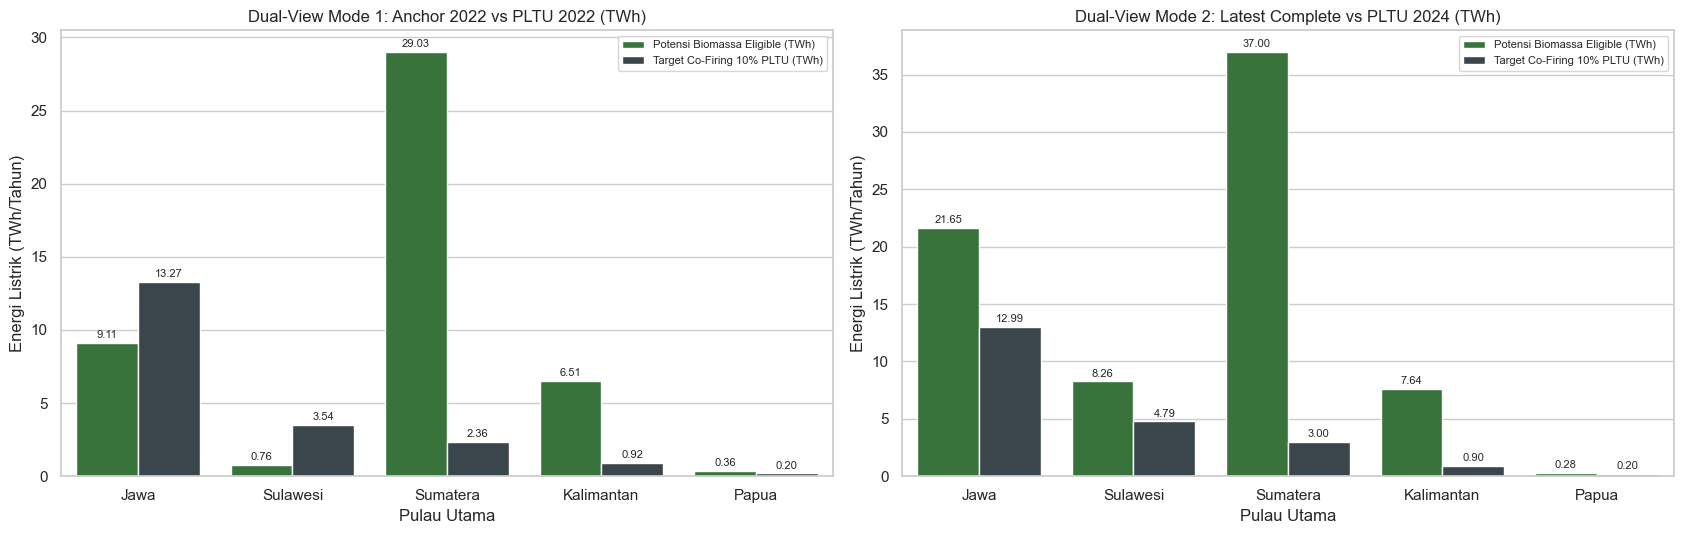

Grafik disimpan ke: D:\UPN VY\Semester 5\BI\Tugas\projectkb\outputs\figures\04_dwh_supply_vs_pltu_dualview.png


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(17, 5.5))

# Panel kiri: Perbandingan Listrik Biomassa Layak Bakar vs Target 10% Co-Firing PLTU (TWh) di 5 Pulau
isl_order = ["Jawa", "Sulawesi", "Sumatera", "Kalimantan", "Papua"]
for ax, mode, title in [
    (axes[0], "ANCHOR_2022", "Dual-View Mode 1: Anchor 2022 vs PLTU 2022 (TWh)"),
    (axes[1], "LATEST_COMPLETE_VS_2024", "Dual-View Mode 2: Latest Complete vs PLTU 2024 (TWh)"),
]:
    sub = vw_dual.loc[vw_dual["view_mode"] == mode].set_index("pulau").reindex(isl_order).reset_index()
    plot_m = pd.DataFrame({
        "Pulau": list(sub["pulau"]) * 2,
        "Metrik": ["Potensi Biomassa Eligible (TWh)"] * len(sub) + ["Target Co-Firing 10% PLTU (TWh)"] * len(sub),
        "TWh": list(sub["eligible_generation_mwh"] / 1e6) + list(sub["target_cofiring_10pct_mwh"] / 1e6),
    })
    sns.barplot(
        data=plot_m,
        x="Pulau",
        y="TWh",
        hue="Metrik",
        palette={"Potensi Biomassa Eligible (TWh)": "#2E7D32", "Target Co-Firing 10% PLTU (TWh)": "#37474F"},
        ax=ax,
    )
    for container in ax.containers:
        ax.bar_label(container, fmt="%.2f", fontsize=8, padding=2)
    ax.set_title(title)
    ax.set_xlabel("Pulau Utama")
    ax.set_ylabel("Energi Listrik (TWh/Tahun)")
    ax.legend(fontsize=8, loc="upper right")

plt.tight_layout()
dwh_fig_path = FIGURES_DIR / "04_dwh_supply_vs_pltu_dualview.png"
plt.savefig(dwh_fig_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"Grafik disimpan ke: {dwh_fig_path}")

**Cara membaca grafik `04_dwh_supply_vs_pltu_dualview.png`:**
Batang hijau menunjukkan total potensi listrik tahunan dari bahan baku berstatus `Eligible` (`FS01`-`FS03`, `FS06`-`FS10`) dengan efisiensi *co-firing* `33%`, sedangkan batang abu-abu menunjukkan kebutuhan listrik untuk rasio `10%` *co-firing* PLTU di masing-masing pulau. Pada panel kiri (`ANCHOR_2022`), `Sumatera` dan `Kalimantan` mencatat surplus besar sementara `Jawa` dan `Sulawesi` belum mencukupi target `10%` akibat hilangnya pelaporan jagung di sentra utama pada 2022. Pada panel kanan (`LATEST_COMPLETE_VS_2024`), seluruh lima pulau utama melebihi target `10%` begitu data penuh jagung 2017 terhitung, dengan `Sumatera` tetap menjadi kontributor terbesar (`37,00 TWh`).

## 7. Verifikasi Otomatis Seluruh Gerbang QA & Pembuatan `DWH_V2_QA_REPORT.md`

Seluruh pengujian otomatis pada *Definition of Done* dan *Success Criteria* Tahap 3 dijalankan langsung pada database `biomass_dwh_v2.sqlite` dan tabel CSV di `warehouse_v2/tables/` untuk memastikan nol pelanggaran integritas, ketepatan rumus fisika hingga batas toleransi 0,01, serta terisolasinya bahan baku `Not Eligible`.

In [8]:
con = sqlite3.connect(db_path)

# 1. Uji semua kriteria terukur Tahap 3
fk_chk = con.execute("PRAGMA foreign_key_check;").fetchall()
assert len(fk_chk) == 0

table_counts = {}
for tname in load_order:
    table_counts[tname] = con.execute(f"SELECT COUNT(*) FROM {tname}").fetchone()[0]
    assert table_counts[tname] > 0

view_names = [
    "vw_feedstock_discovery_matrix",
    "vw_regional_potential_anchor_2022",
    "vw_regional_potential_latest_complete",
    "vw_supply_vs_pltu_5_pulau_dualview",
    "vw_cofiring_simulator_base",
]
view_counts = {}
for vname in view_names:
    view_counts[vname] = con.execute(f"SELECT COUNT(*) FROM {vname}").fetchone()[0]
    assert view_counts[vname] > 0

assert table_counts["dim_feedstock"] == 10
assert table_counts["dim_location"] == 560
assert table_counts["dim_conversion_tech"] == 2
assert table_counts["dim_time"] == 16
assert table_counts["dim_power_plant"] == 119
assert table_counts["fact_pltu_operations"] == 548
assert view_counts["vw_supply_vs_pltu_5_pulau_dualview"] == 10

# Cek akurasi rumus GJ & MWh pada 100% baris fact_feedstock_potential (deviasi <= 0.01)
max_formula_dev = con.execute('''
    SELECT
        MAX(ABS(e.total_energy_potential_gj - (e.estimated_supply_tons * e.effective_lhv_mj_kg))),
        MAX(ABS(e.estimated_generation_mwh - ((e.total_energy_potential_gj * (ct.efficiency_pct / 100.0)) / 3.6)))
    FROM fact_feedstock_potential e
    JOIN dim_conversion_tech ct ON e.tech_key = ct.tech_key
''').fetchone()
assert max_formula_dev[0] <= 0.01 and max_formula_dev[1] <= 0.01, f"Deviasi rumus > 0.01: {max_formula_dev}"

# Cek konsistensi himpunan pulau dim_location (regional) vs dim_power_plant
loc_islands = {r[0] for r in con.execute("SELECT DISTINCT pulau FROM dim_location WHERE level_wilayah != 'NASIONAL'").fetchall()}
pltu_islands = {r[0] for r in con.execute("SELECT DISTINCT pulau FROM dim_power_plant").fetchall()}
assert loc_islands == pltu_islands

# Cek nol kontribusi FS04/FS05 pada is_boiler_eligible = 1
fs04_05_elig = con.execute('''
    SELECT COUNT(*) FROM fact_feedstock_potential e
    JOIN dim_feedstock f ON e.feedstock_key = f.feedstock_key
    WHERE f.feedstock_id IN ('FS04', 'FS05') AND e.is_boiler_eligible = 1
''').fetchone()[0]
assert fs04_05_elig == 0

# Cek konsistensi jumlah baris tabel SQLite vs CSV ekspor
csv_parity = []
for tname in load_order:
    csv_cnt = len(pd.read_csv(NEW_WH_TABLES / f"{tname}.csv"))
    assert csv_cnt == table_counts[tname], f"Selisih baris CSV vs SQLite pada {tname}: {csv_cnt} vs {table_counts[tname]}"
    csv_parity.append(f"{tname}={csv_cnt:,}")

con.close()

# Tulis DWH_V2_QA_REPORT.md
qa_lines = [
    "# Laporan QA Star Schema Data Warehouse V2 (`warehouse_v2/biomass_dwh_v2.sqlite`)",
    "",
    f"Tanggal QA: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}  ",
    "Status Validasi Otomatis: 10/10 PASS (0 pelanggaran Foreign Key, 0 duplikat kunci, 0 kebocoran bahan baku Not Eligible)",
    "",
    "## 1. Inventaris Tabel & Analytical Views (`warehouse_v2/`)",
    "",
    "| Jenis | Nama Objek | Jumlah Baris |",
    "| :--- | :--- | :---: |",
]
for k, v in table_counts.items():
    typ = "Dimension" if k.startswith("dim_") else "Fact"
    qa_lines.append(f"| {typ} | `{k}` | {v:,} |")
for k, v in view_counts.items():
    qa_lines.append(f"| View | `{k}` | {v:,} |")

qa_lines += [
    "",
    "## 2. Pengujian Integritas & Rekonsiliasi Otomatis",
    "",
    "| No | Pengujian QA | Status | Bukti Terukur |",
    "| :---: | :--- | :---: | :--- |",
    "| 1 | Foreign Key Integrity (`PRAGMA foreign_key_check`) | PASS | 0 pelanggaran FK |",
    f"| 2 | Kelengkapan 7 Tabel & 5 Views Non-Kosong | PASS | 7 tabel ({sum(table_counts.values()):,} baris) & 5 views seluruhnya terisi |",
    f"| 3 | Konsistensi Jumlah Baris SQLite vs 7 CSV Ekspor | PASS | 100% cocok (`dim_feedstock=10`, `dim_location=560`, `fact_feedstock_potential={table_counts['fact_feedstock_potential']:,}`, `fact_pltu_operations=548`) |",
    f"| 4 | Rekonsiliasi Kayu KLHK PHL Tahun Jangkar 2022 | PASS | `2022 = {klhk_reconcile.loc[2022, 'Total_Kayu_Bulat_m3']:,.2f} m3` (0 provinsi gagal cocok) |",
    f"| 5 | Rekonsiliasi Kayu KLHK PHL Tahun Terbaru 2024 | PASS | `2024 = {klhk_reconcile.loc[2024, 'Total_Kayu_Bulat_m3']:,.2f} m3` (selisih 0,0 m3 vs PDF KLHK) |",
    "| 6 | Harmonisasi Lokasi & Pulau (`dim_location` vs `dim_power_plant`) | PASS | 560 baris (`514` kab/kota + `38` prov + `7` pulau + `1` nasional), 7 pulau cocok 100% |",
    "| 7 | Staging PLTU & Rekonsiliasi CREA 2024 | PASS | 119 PLTU unik, 548 baris (`500` CT + `48` CREA), CREA 2024 = 18.342,0 MW / 1.457.720,0 ton / 1.506.076,0 MWh |",
    f"| 8 | Ketepatan Rumus Energi GJ & MWh (`fact_feedstock_potential`) | PASS | Deviasi maksimum GJ = {max_formula_dev[0]:.6f}, MWh = {max_formula_dev[1]:.6f} (ambang <= 0,01) |",
    "| 9 | Isolasi Feedstock Gugur (`FS04` & `FS05`) | PASS | 0 baris berkode `is_boiler_eligible = 1`, 0 ton masuk ke pasokan layak bakar PLTU |",
    "| 10 | Cakupan `vw_supply_vs_pltu_5_pulau_dualview` | PASS | Tepat 10 baris (5 pulau x 2 mode Dual-View) |",
    "",
    "## 3. Ringkasan Suplai Eligible (`Co-Firing 33%`) vs Permintaan PLTU 5 Pulau (`vw_supply_vs_pltu_5_pulau_dualview`)",
    "",
    "| Mode Dual-View | Pulau | PLTU CT | Generasi PLTU (GWh) | Target 10% (GWh) | Suplai Eligible (Juta Ton) | Potensi Listrik Eligible (GWh) | Rasio vs Target 10% |",
    "| :--- | :--- | :---: | :---: | :---: | :---: | :---: | :---: |",
]
for _, r in vw_dual.iterrows():
    qa_lines.append(
        f"| `{r['view_mode']}` | {r['pulau']} | {int(r['pltu_count_ct'])} | "
        f"{r['pltu_generation_mwh']/1e3:,.1f} | {r['target_cofiring_10pct_mwh']/1e3:,.1f} | "
        f"{r['eligible_supply_tons']/1e6:,.2f} | {r['eligible_generation_mwh']/1e3:,.1f} | "
        f"{r['coverage_vs_10pct_cofiring_pct']:,.1f}% |"
    )

qa_report_path = NEW_WH_DIR / "DWH_V2_QA_REPORT.md"
qa_report_path.write_text("\n".join(qa_lines) + "\n", encoding="utf-8")

print("SELURUH GERBANG VERIFIKASI TAHAP 3 LULUS:")
print(f"  - Laporan QA tersimpan di : {qa_report_path}")
print(f"  - File siap BI (7 CSV)    : {NEW_WH_TABLES}")
print(f"  - Database SQLite         : {db_path}")
print("\nSerah Terima:")
print("  -> Lanjut ke Tahap 4 (Dashboard BI 3 Halaman) memakai warehouse_v2/biomass_dwh_v2.sqlite dan 7 CSV di warehouse_v2/tables/")

SELURUH GERBANG VERIFIKASI TAHAP 3 LULUS:
  - Laporan QA tersimpan di : D:\UPN VY\Semester 5\BI\Tugas\projectkb\warehouse_v2\DWH_V2_QA_REPORT.md
  - File siap BI (7 CSV)    : D:\UPN VY\Semester 5\BI\Tugas\projectkb\warehouse_v2\tables
  - Database SQLite         : D:\UPN VY\Semester 5\BI\Tugas\projectkb\warehouse_v2\biomass_dwh_v2.sqlite

Serah Terima:
  -> Lanjut ke Tahap 4 (Dashboard BI 3 Halaman) memakai warehouse_v2/biomass_dwh_v2.sqlite dan 7 CSV di warehouse_v2/tables/
